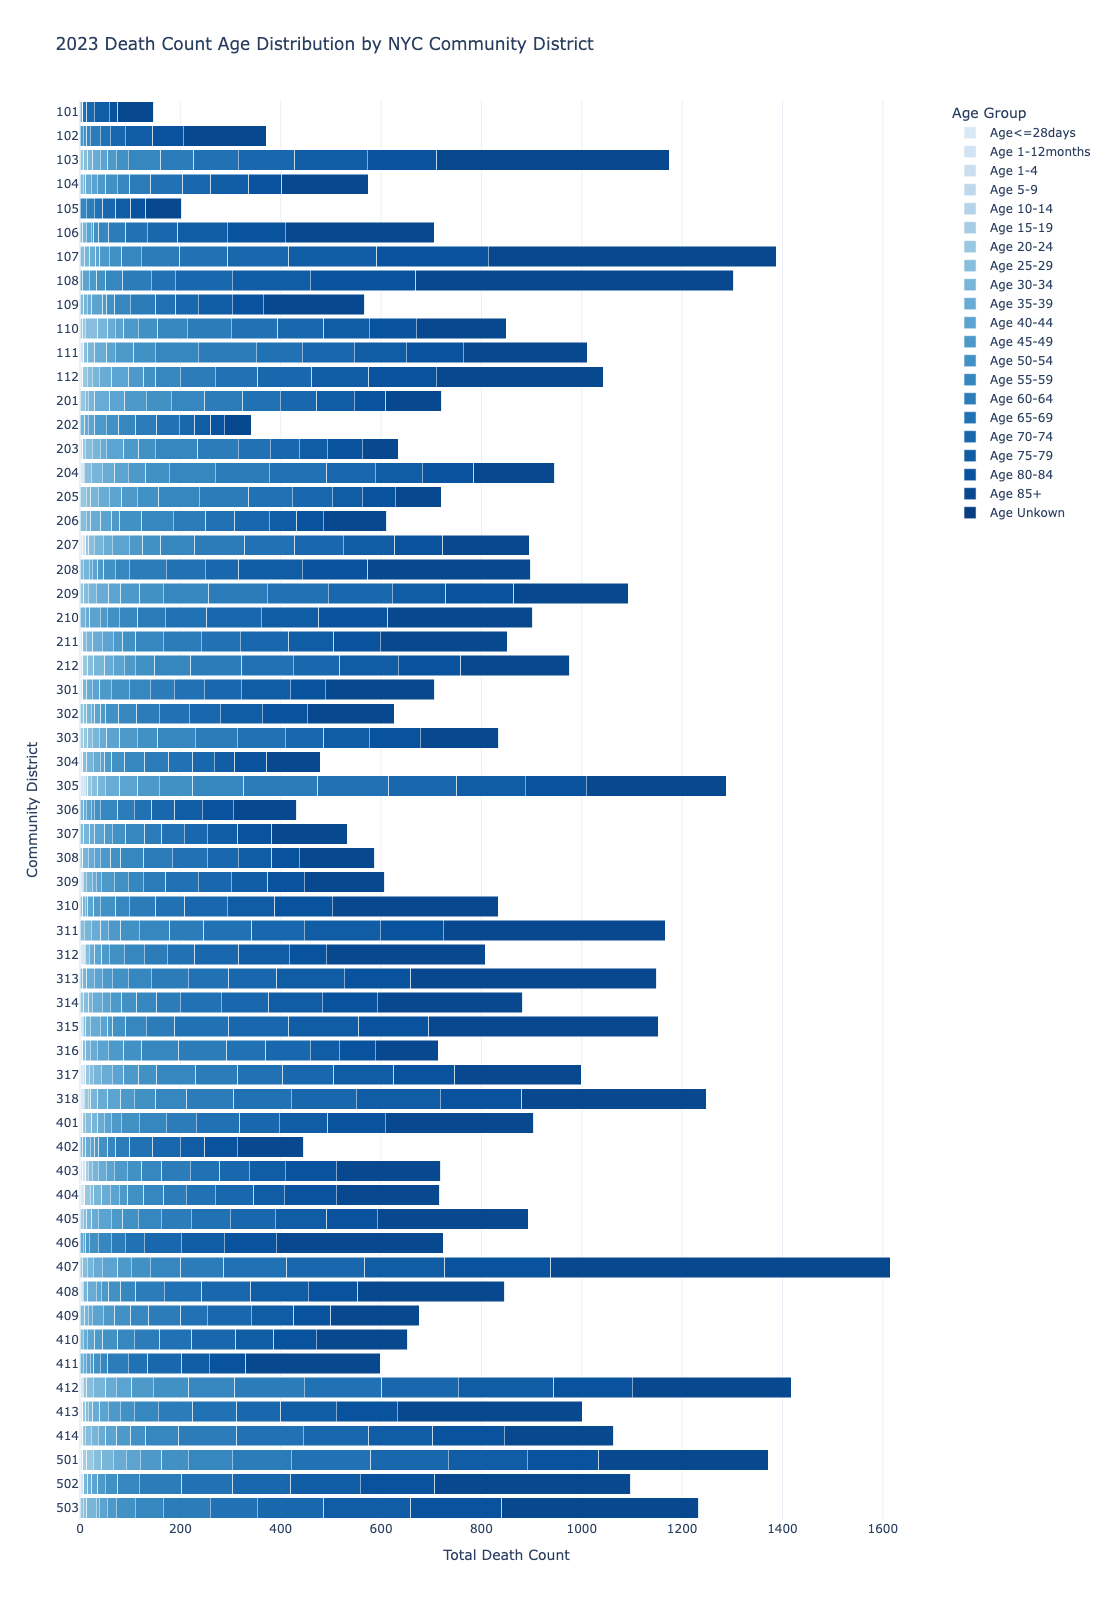

In [16]:

import pandas as pd
import plotly.express as px

# Load CSV
df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")

# Age group columns
age_columns = [
    "Age<=28days", "Age 1-12months", "Age 1-4",
    "Age 5-9", "Age 10-14", "Age 15-19",
    "Age 20-24", "Age 25-29", "Age 30-34",
    "Age 35-39", "Age 40-44", "Age 45-49",
    "Age 50-54", "Age 55-59", "Age 60-64",
    "Age 65-69", "Age 70-74", "Age 75-79",
    "Age 80-84", "Age 85+", "Age Unkown"
]

# Convert age columns to numeric
for col in age_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", ""),
        errors="coerce"
    ).fillna(0)

# Convert community district to string
df["commntydst"] = df["commntydst"].astype(str)

# Aggregate counts by community district
df_grouped = df.groupby(
    "commntydst", as_index=False
)[age_columns].sum()

# Convert wide data to long format
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=age_columns,
    var_name="Age Group",
    value_name="Count"
)

# Calculate total deaths for each community district
df_long["District_Total"] = df_long.groupby(
    "commntydst"
)["Count"].transform("sum")

# Calculate percentage of deaths in each age group
df_long["Percentage"] = (
    df_long["Count"] / df_long["District_Total"] * 100
).fillna(0)

# Create horizontal stacked bar chart
fig = px.bar(
    df_long,
    x="Count",
    y="commntydst",
    color="Age Group",
    orientation="h",
    barmode="stack",
    title="2023 Death Count Age Distribution by NYC Community District",
    labels={
        "Count": "Death Count",
        "commntydst": "Community District"
    },
    category_orders={
        "Age Group": age_columns,
        "commntydst": sorted(df_grouped["commntydst"].unique())
    },
    custom_data=["Percentage", "District_Total"],
    height=1600
)

# Customize hover information
fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{y}<br>"
        "<b>Age Group:</b> %{fullData.name}<br>"
        "<b>Death Count:</b> %{x:,.0f}<br>"
        "<b>Percentage of District Deaths:</b> %{customdata[0]:.2f}%<br>"
        "<b>Total District Deaths:</b> %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

# Customize layout
fig.update_layout(
    xaxis_title="Total Death Count",
    yaxis_title="Community District",
    legend_title="Age Group",
    legend=dict(
        orientation="h",
        y=-0.12,
        x=0.5,
        xanchor="center"
    ),
    bargap=0.15,
    template="plotly_white",
    hovermode="closest"
)

# Display community districts as categories
fig.update_yaxes(type="category")

# Display chart
 

# Create age-based blue color gradient
age_colors = px.colors.sample_colorscale(
    "Blues",
    [0.15 + i * 0.8 / (len(age_columns) - 1)
     for i in range(len(age_columns))]
)

age_color_map = dict(zip(age_columns, age_colors))

# Create horizontal stacked bar chart
fig = px.bar(
    df_long,
    x="Count",
    y="commntydst",
    color="Age Group",
    orientation="h",
    barmode="stack",
    title="2023 Death Count Age Distribution by NYC Community District",
    labels={
        "Count": "Death Count",
        "commntydst": "Community District"
    },
    category_orders={
        "Age Group": age_columns,
        "commntydst": sorted(df_grouped["commntydst"].unique())
    },
    color_discrete_map=age_color_map,
    custom_data=["Percentage", "District_Total"],
    height=1600
)

# Customize hover information
fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{y}<br>"
        "<b>Age Group:</b> %{fullData.name}<br>"
        "<b>Death Count:</b> %{x:,.0f}<br>"
        "<b>Percentage of District Deaths:</b> %{customdata[0]:.2f}%<br>"
        "<b>Total District Deaths:</b> %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    xaxis_title="Total Death Count",
    yaxis_title="Community District",
    legend_title="Age Group",
    bargap=0.15,
    template="plotly_white",
    hovermode="closest"
)

fig.update_yaxes(type="category")

fig.show()

 

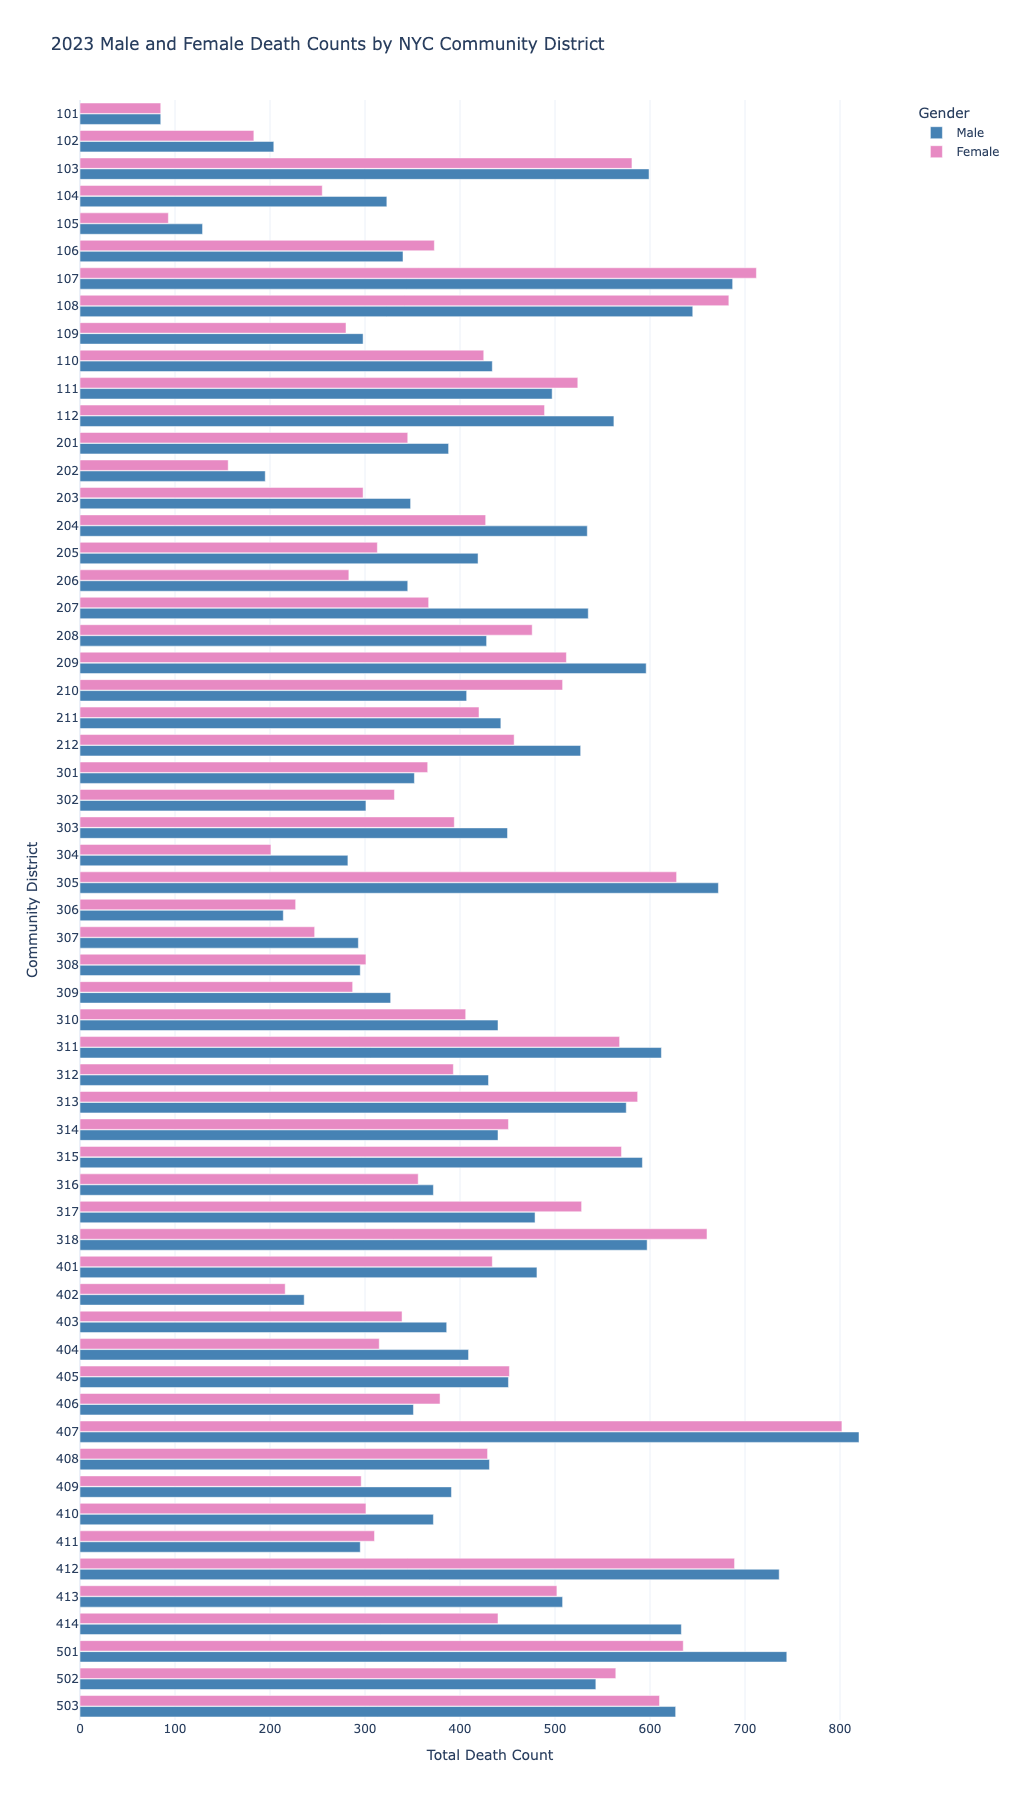

In [18]:
print(df.columns.tolist())
print(df.head(10).to_string())

['commntydst', 'Male', 'Female', 'Age<=28days', 'Age 1-12months', 'Age 1-4', 'Age 5-9', 'Age 10-14', 'Age 15-19', 'Age 20-24', 'Age 25-29', 'Age 30-34', 'Age 35-39', 'Age 40-44', 'Age 45-49', 'Age 50-54', 'Age 55-59', 'Age 60-64', 'Age 65-69', 'Age 70-74', 'Age 75-79', 'Age 80-84', 'Age 85+', 'Age Unkown', 'Male_Age<=28days', 'Male_Age 1-12months', 'Male_Age 1-4', 'Male_Age 5-9', 'Male_Age 10-14', 'Male_Age 15-19', 'Male_Age 20-24', 'Male_Age 25-29', 'Male_Age 30-34', 'Male_Age 35-39', 'Male_Age 40-44', 'Male_Age 45-49', 'Male_Age 50-54', 'Male_Age 55-59', 'Male_Age 60-64', 'Male_Age 65-69', 'Male_Age 70-74', 'Male_Age 75-79', 'Male_Age 80-84', 'Male_Age 85+', 'Male_Age Unkown', 'Female_Age<=28days', 'Female_Age 1-12months', 'Female_Age 1-4', 'Female_Age 5-9', 'Female_Age 10-14', 'Female_Age 15-19', 'Female_Age 20-24', 'Female_Age 25-29', 'Female_Age 30-34', 'Female_Age 35-39', 'Female_Age 40-44', 'Female_Age 45-49', 'Female_Age 50-54', 'Female_Age 55-59', 'Female_Age 60-64', 'Female_A

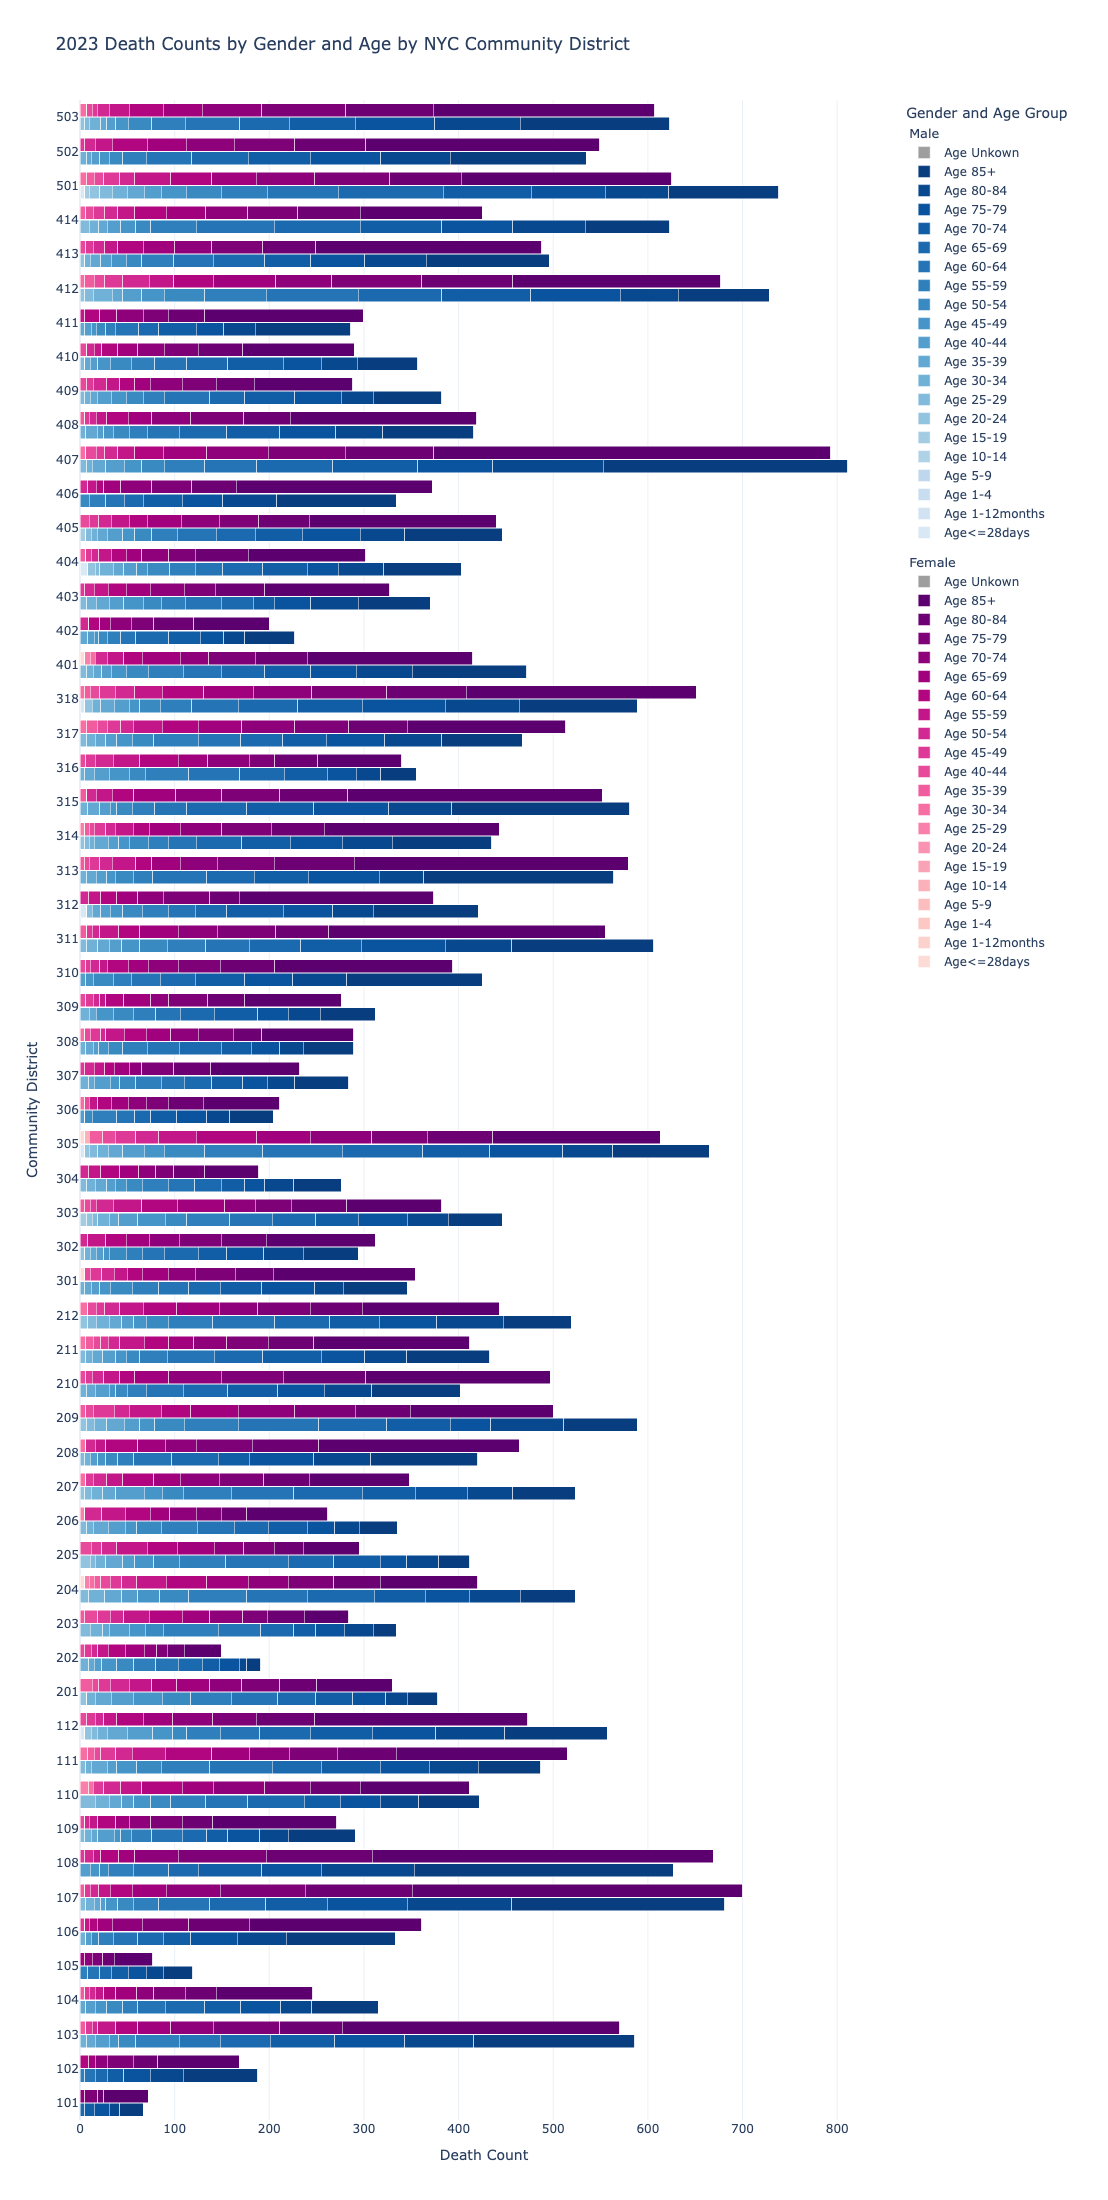

In [19]:

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px

# Load CSV
df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")

# Age groups in chronological order
age_columns = [
    "Age<=28days", "Age 1-12months", "Age 1-4",
    "Age 5-9", "Age 10-14", "Age 15-19",
    "Age 20-24", "Age 25-29", "Age 30-34",
    "Age 35-39", "Age 40-44", "Age 45-49",
    "Age 50-54", "Age 55-59", "Age 60-64",
    "Age 65-69", "Age 70-74", "Age 75-79",
    "Age 80-84", "Age 85+", "Age Unkown"
]

genders = ["Male", "Female"]

# Select the age-by-gender columns
gender_age_columns = [
    f"{gender}_{age}"
    for gender in genders
    for age in age_columns
]

# Convert death counts to numeric
for col in gender_age_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# Clean community district codes
df["commntydst"] = (
    df["commntydst"].astype(str).str.strip()
)

# Aggregate counts by community district
df_grouped = df.groupby(
    "commntydst", as_index=False
)[gender_age_columns].sum()

# Reshape data into long format
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=gender_age_columns,
    var_name="Gender_Age",
    value_name="Count"
)

# Separate gender and age group
df_long[["Gender", "Age Group"]] = (
    df_long["Gender_Age"].str.split(
        "_", n=1, expand=True
    )
)

# Calculate total deaths for each gender
# within each community district
df_long["Gender_Total"] = df_long.groupby(
    ["commntydst", "Gender"]
)["Count"].transform("sum")

# Calculate percentage of deaths within gender
df_long["Percentage"] = (
    df_long["Count"] /
    df_long["Gender_Total"].replace(0, np.nan)
    * 100
).fillna(0)

# -----------------------------------------
# CREATE COLOR GRADIENTS
# -----------------------------------------

known_ages = [
    age for age in age_columns
    if age != "Age Unkown"
]

positions = np.linspace(0.15, 0.95, len(known_ages))

# Male: light blue to dark blue
male_colors = px.colors.sample_colorscale(
    "Blues", positions
)

# Female: light pink to dark pink
female_colors = px.colors.sample_colorscale(
    "RdPu", positions
)

male_color_map = dict(zip(known_ages, male_colors))
female_color_map = dict(zip(known_ages, female_colors))

# Unknown age is gray
male_color_map["Age Unkown"] = "#9E9E9E"
female_color_map["Age Unkown"] = "#9E9E9E"

# -----------------------------------------
# CREATE HORIZONTAL STACKED BAR CHART
# -----------------------------------------

districts = sorted(
    df_long["commntydst"].unique(),
    key=lambda x: int(x) if x.isdigit() else float("inf")
)

fig = go.Figure()

# Create separate stacked bars for each gender
for gender in genders:

    color_map = (
        male_color_map if gender == "Male"
        else female_color_map
    )

    for age in age_columns:

        subset = df_long[
            (df_long["Gender"] == gender) &
            (df_long["Age Group"] == age)
        ].set_index("commntydst").reindex(districts)

        counts = subset["Count"].fillna(0)
        percentages = subset["Percentage"].fillna(0)
        totals = subset["Gender_Total"].fillna(0)

        # Stack ages within each gender bar
        fig.add_trace(
            go.Bar(
                x=counts,
                y=districts,
                orientation="h",
                name=age,
                offsetgroup=gender,
                legendgroup=gender,
                legendgrouptitle_text=(
                    gender if age == age_columns[0]
                    else None
                ),
                marker_color=color_map[age],
                customdata=np.column_stack([
                    percentages,
                    totals
                ]),
                hovertemplate=(
                    "<b>Community District:</b> %{y}<br>"
                    f"<b>Gender:</b> {gender}<br>"
                    f"<b>Age Group:</b> {age}<br>"
                    "<b>Death Count:</b> %{x:,.0f}<br>"
                    "<b>Percentage of Gender Deaths:</b> "
                    "%{customdata[0]:.2f}%<br>"
                    "<b>Total Gender Deaths:</b> "
                    "%{customdata[1]:,.0f}"
                    "<extra></extra>"
                )
            )
        )

# -----------------------------------------
# CUSTOMIZE CHART
# -----------------------------------------

fig.update_layout(
    title=(
        "2023 Death Counts by Gender and Age "
        "by NYC Community District"
    ),
    xaxis_title="Death Count",
    yaxis_title="Community District",
    barmode="stack",
    bargap=0.2,
    bargroupgap=0.05,
    height=2200,
    template="plotly_white",
    hovermode="closest",
    legend=dict(
        title="Gender and Age Group",
        orientation="v",
        x=1.02,
        y=1,
        groupclick="toggleitem"
    ),
    margin=dict(
        l=80,
        r=220,
        t=100,
        b=80
    )
)

# Sort community districts
fig.update_yaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts
)

# Display chart
fig.show()


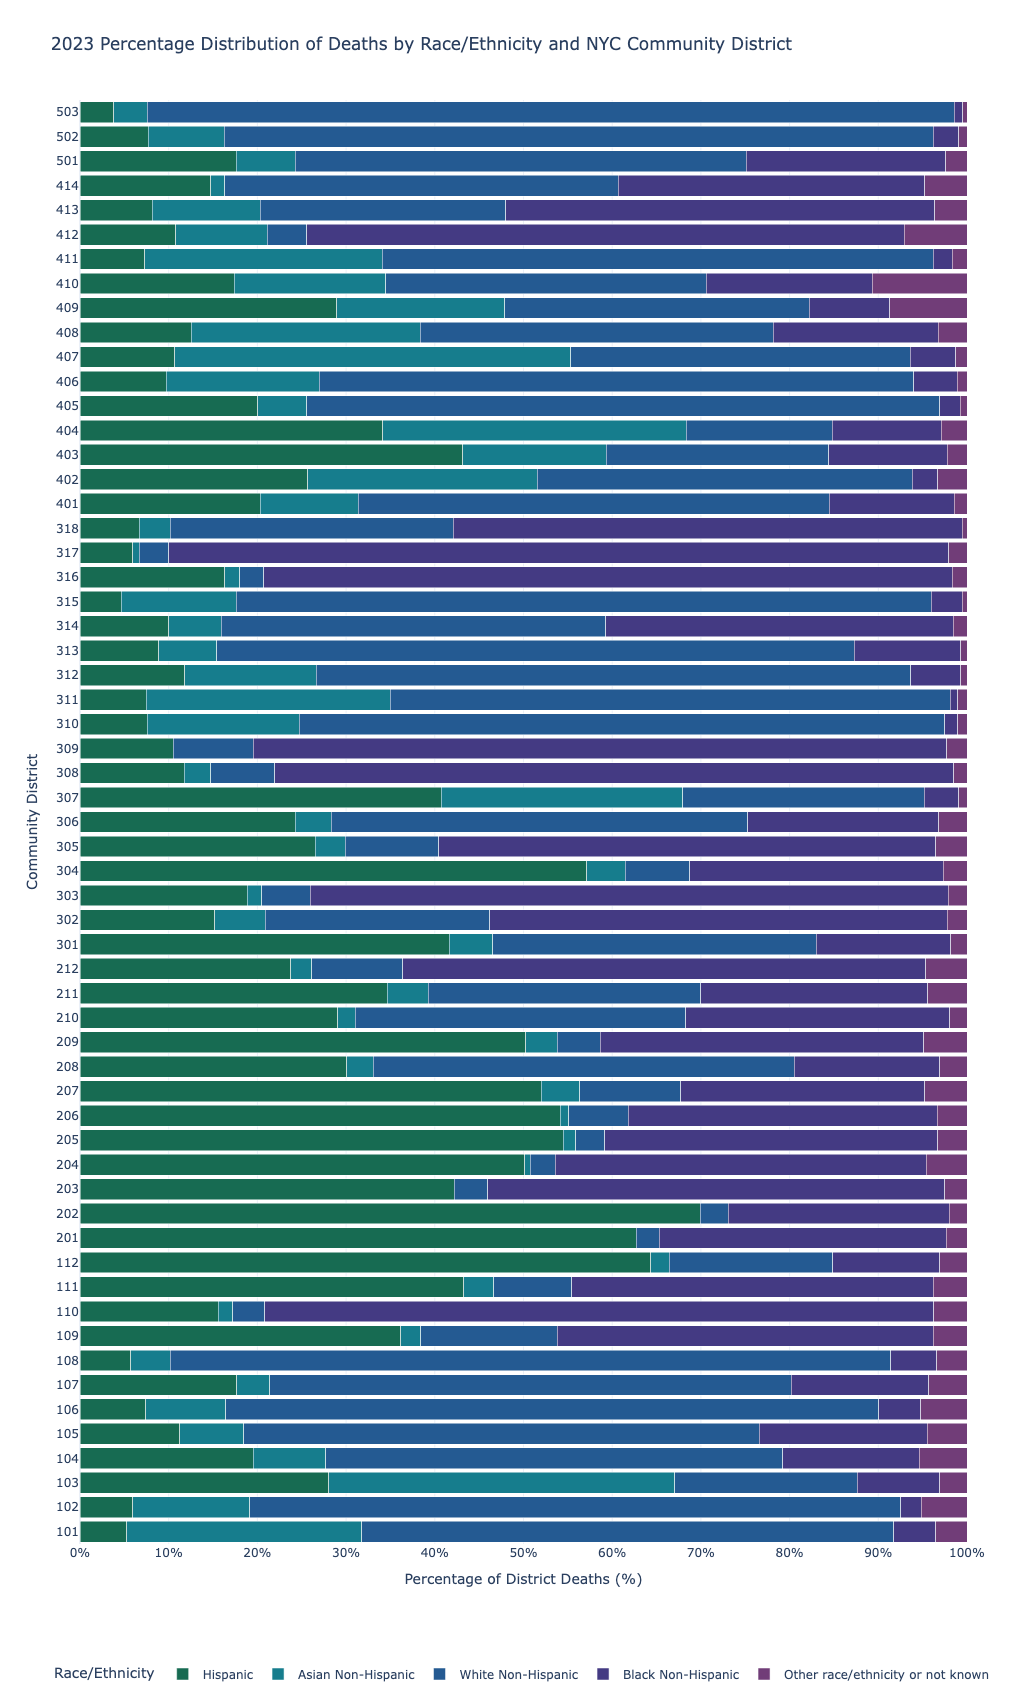

In [20]:

import pandas as pd
import numpy as np
import plotly.express as px

# Load CSV
df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")

# Race/ethnicity columns
race_columns = [
    "Hispanic",
    "Asian Non-Hispanic",
    "White Non-Hispanic",
    "Black Non-Hispanic",
    "Other race/ethnicity or not known"
]

# Convert race columns to numeric
for col in race_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# Convert community district to string
df["commntydst"] = df["commntydst"].astype(str).str.strip()

# Aggregate death counts by community district
df_grouped = df.groupby(
    "commntydst", as_index=False
)[race_columns].sum()

# Convert wide data into long format
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=race_columns,
    var_name="Race/Ethnicity",
    value_name="Count"
)

# Calculate total deaths within each district
df_long["District_Total"] = df_long.groupby(
    "commntydst"
)["Count"].transform("sum")

# Calculate percentage of deaths by race/ethnicity
df_long["Percentage"] = (
    df_long["Count"] /
    df_long["District_Total"].replace(0, np.nan)
    * 100
).fillna(0)

# -----------------------------------------
# CUSTOM COLOR PALETTE
# -----------------------------------------

race_color_map = {
    "Hispanic": "#176B52",
    "Asian Non-Hispanic": "#167D8D",
    "White Non-Hispanic": "#245A92",
    "Black Non-Hispanic": "#443A83",
    "Other race/ethnicity or not known": "#713D78"
}

# Sort districts numerically
districts = sorted(
    df_grouped["commntydst"].unique(),
    key=lambda x: int(x) if x.isdigit() else float("inf")
)

# -----------------------------------------
# CREATE HORIZONTAL STACKED BAR CHART
# -----------------------------------------

fig = px.bar(
    df_long,
    x="Percentage",
    y="commntydst",
    color="Race/Ethnicity",
    orientation="h",
    barmode="stack",
    title=(
        "2023 Percentage Distribution of Deaths "
        "by Race/Ethnicity and NYC Community District"
    ),
    labels={
        "Percentage": "Percentage of District Deaths (%)",
        "commntydst": "Community District"
    },
    color_discrete_map=race_color_map,
    category_orders={
        "Race/Ethnicity": race_columns,
        "commntydst": districts
    },
    custom_data=["Count", "District_Total"],
    height=1700
)

# -----------------------------------------
# CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{y}<br>"
        "<b>Race/Ethnicity:</b> %{fullData.name}<br>"
        "<b>Percentage of District Deaths:</b> %{x:.2f}%<br>"
        "<b>Death Count:</b> %{customdata[0]:,.0f}<br>"
        "<b>Total District Deaths:</b> %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

# -----------------------------------------
# CUSTOMIZE LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="Percentage of District Deaths (%)",
    yaxis_title="Community District",
    legend_title="Race/Ethnicity",
    bargap=0.15,
    template="plotly_white",
    hovermode="closest",
    height=1700,
    legend=dict(
        orientation="h",
        y=-0.08,
        x=0.5,
        xanchor="center"
    ),
    margin=dict(
        l=80,
        r=50,
        t=100,
        b=120
    )
)

# Set percentage axis from 0 to 100
fig.update_xaxes(
    range=[0, 100],
    ticksuffix="%",
    dtick=10
)

# Treat community districts as categories
fig.update_yaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts
)

# Display chart
fig.show()


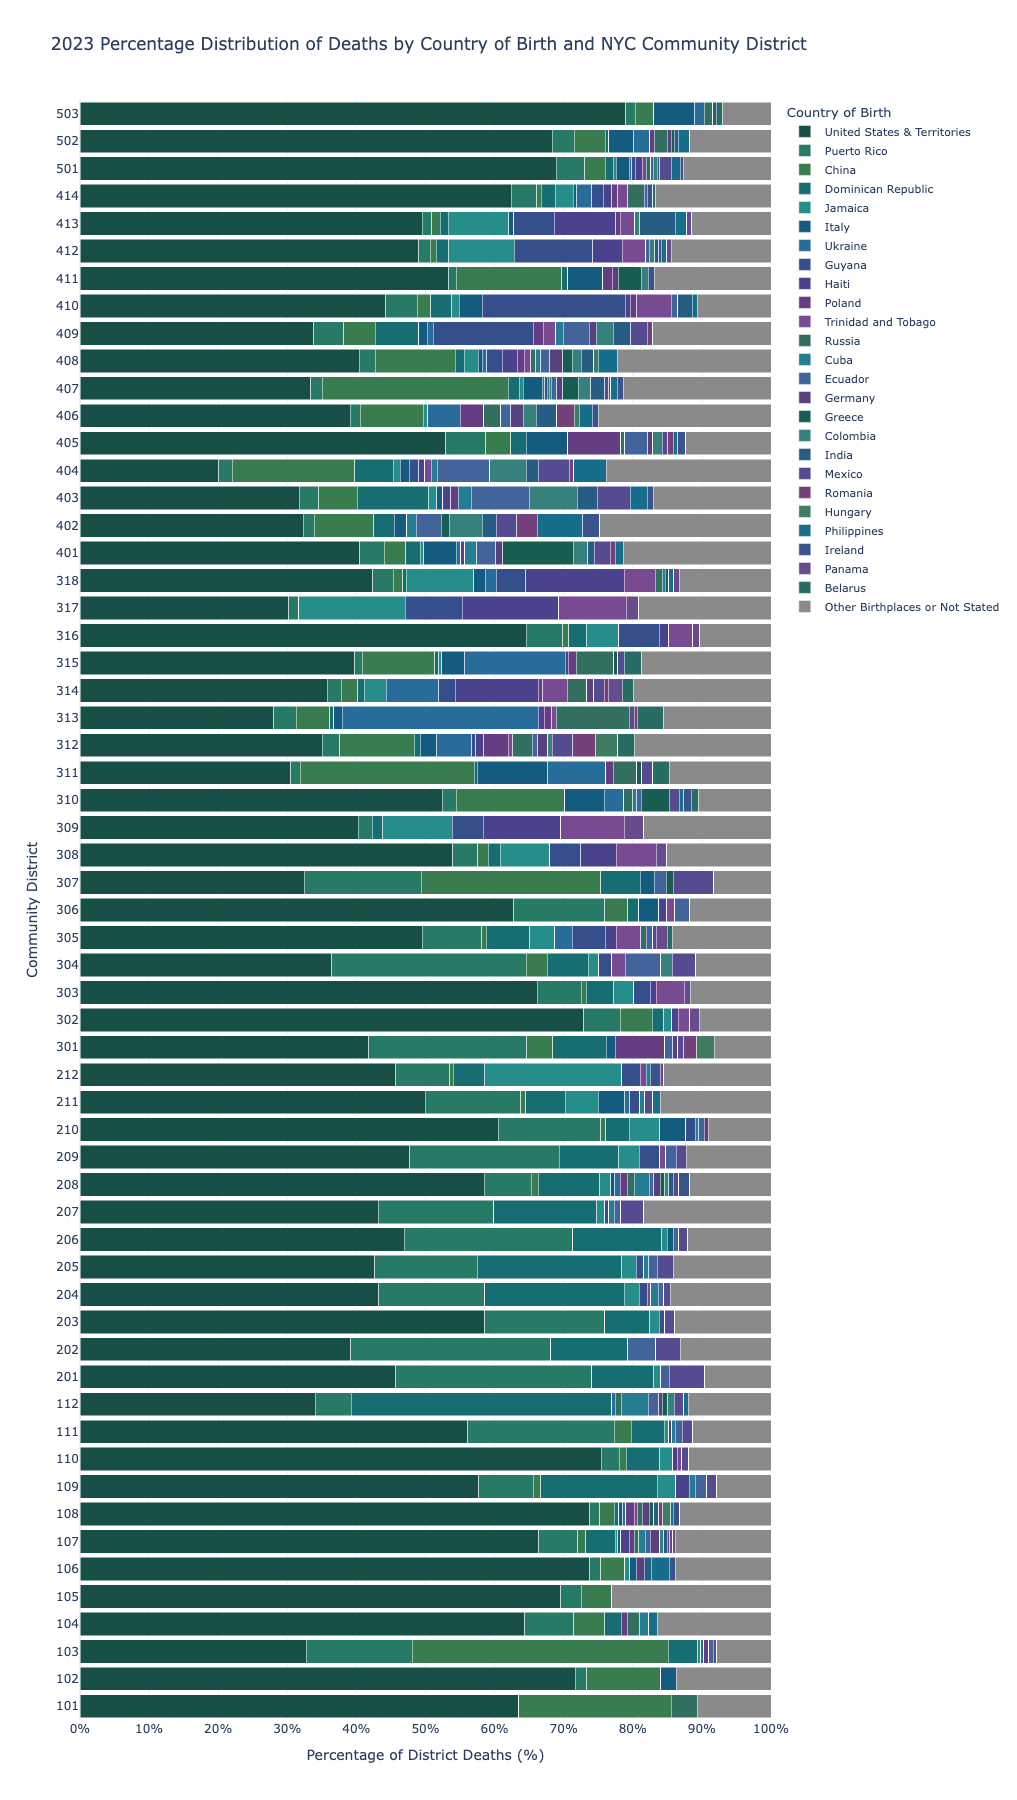

In [21]:

import pandas as pd
import numpy as np
import plotly.express as px

# Load CSV
df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")

# Birthplace columns
birthplace_columns = [
    "United States & Territories",
    "Puerto Rico",
    "China",
    "Dominican Republic",
    "Jamaica",
    "Italy",
    "Ukraine",
    "Guyana",
    "Haiti",
    "Poland",
    "Trinidad and Tobago",
    "Russia",
    "Cuba",
    "Ecuador",
    "Germany",
    "Greece",
    "Colombia",
    "India",
    "Mexico",
    "Romania",
    "Hungary",
    "Philippines",
    "Ireland",
    "Panama",
    "Belarus",
    "Other Birthplaces or Not Stated"
]

# Convert birthplace columns to numeric
for col in birthplace_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# Clean community district codes
df["commntydst"] = (
    df["commntydst"].astype(str).str.strip()
)

# Aggregate death counts by district
df_grouped = df.groupby(
    "commntydst", as_index=False
)[birthplace_columns].sum()

# Convert wide data to long format
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=birthplace_columns,
    var_name="Birthplace",
    value_name="Count"
)

# Calculate total deaths by community district
df_long["District_Total"] = df_long.groupby(
    "commntydst"
)["Count"].transform("sum")

# Calculate percentage of district deaths
df_long["Percentage"] = (
    df_long["Count"] /
    df_long["District_Total"].replace(0, np.nan)
    * 100
).fillna(0)

# -----------------------------------------
# CUSTOM DARK GREEN, BLUE, PURPLE PALETTE
# -----------------------------------------

birthplace_colors = [
    "#174F46",  # Dark green
    "#277A65",  # Forest green
    "#397C50",  # Green
    "#166D72",  # Dark teal
    "#258D8A",  # Teal
    "#145B80",  # Deep blue
    "#276C9B",  # Blue
    "#354F8C",  # Indigo blue
    "#4B428D",  # Indigo
    "#643D83",  # Purple
    "#784A91",  # Violet
    "#326F60",
    "#247D91",
    "#42649A",
    "#58427E",
    "#175D52",
    "#36817C",
    "#285D83",
    "#554B91",
    "#74417A",
    "#407C62",
    "#166E8B",
    "#39548C",
    "#674B8D",
    "#296C65",
    "#8A8A8A"   # Other / not stated
]

birthplace_color_map = dict(
    zip(birthplace_columns, birthplace_colors)
)

# Sort community districts numerically
districts = sorted(
    df_grouped["commntydst"].unique(),
    key=lambda x: int(x) if x.isdigit() else float("inf")
)

# -----------------------------------------
# CREATE HORIZONTAL STACKED BAR CHART
# -----------------------------------------

fig = px.bar(
    df_long,
    x="Percentage",
    y="commntydst",
    color="Birthplace",
    orientation="h",
    barmode="stack",
    title=(
        "2023 Percentage Distribution of Deaths "
        "by Country of Birth and NYC Community District"
    ),
    labels={
        "Percentage": "Percentage of District Deaths (%)",
        "commntydst": "Community District"
    },
    color_discrete_map=birthplace_color_map,
    category_orders={
        "Birthplace": birthplace_columns,
        "commntydst": districts
    },
    custom_data=["Count", "District_Total"],
    height=1800
)

# -----------------------------------------
# CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{y}<br>"
        "<b>Birthplace:</b> %{fullData.name}<br>"
        "<b>Percentage of District Deaths:</b> %{x:.2f}%<br>"
        "<b>Death Count:</b> %{customdata[0]:,.0f}<br>"
        "<b>Total District Deaths:</b> %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

# -----------------------------------------
# CUSTOMIZE LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="Percentage of District Deaths (%)",
    yaxis_title="Community District",
    legend_title="Country of Birth",
    bargap=0.15,
    template="plotly_white",
    hovermode="closest",
    height=1800,
    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11)
    ),
    margin=dict(
        l=80,
        r=240,
        t=100,
        b=80
    )
)

# Percentage axis from 0 to 100
fig.update_xaxes(
    range=[0, 100],
    ticksuffix="%",
    dtick=10
)

# Community districts as categories
fig.update_yaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts
)

fig.show()


/var/folders/pl/hh80xm6x4hvcgdgydq01cwt00000gn/T/ipykernel_2207/624917018.py:119: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Other cancers"] = (


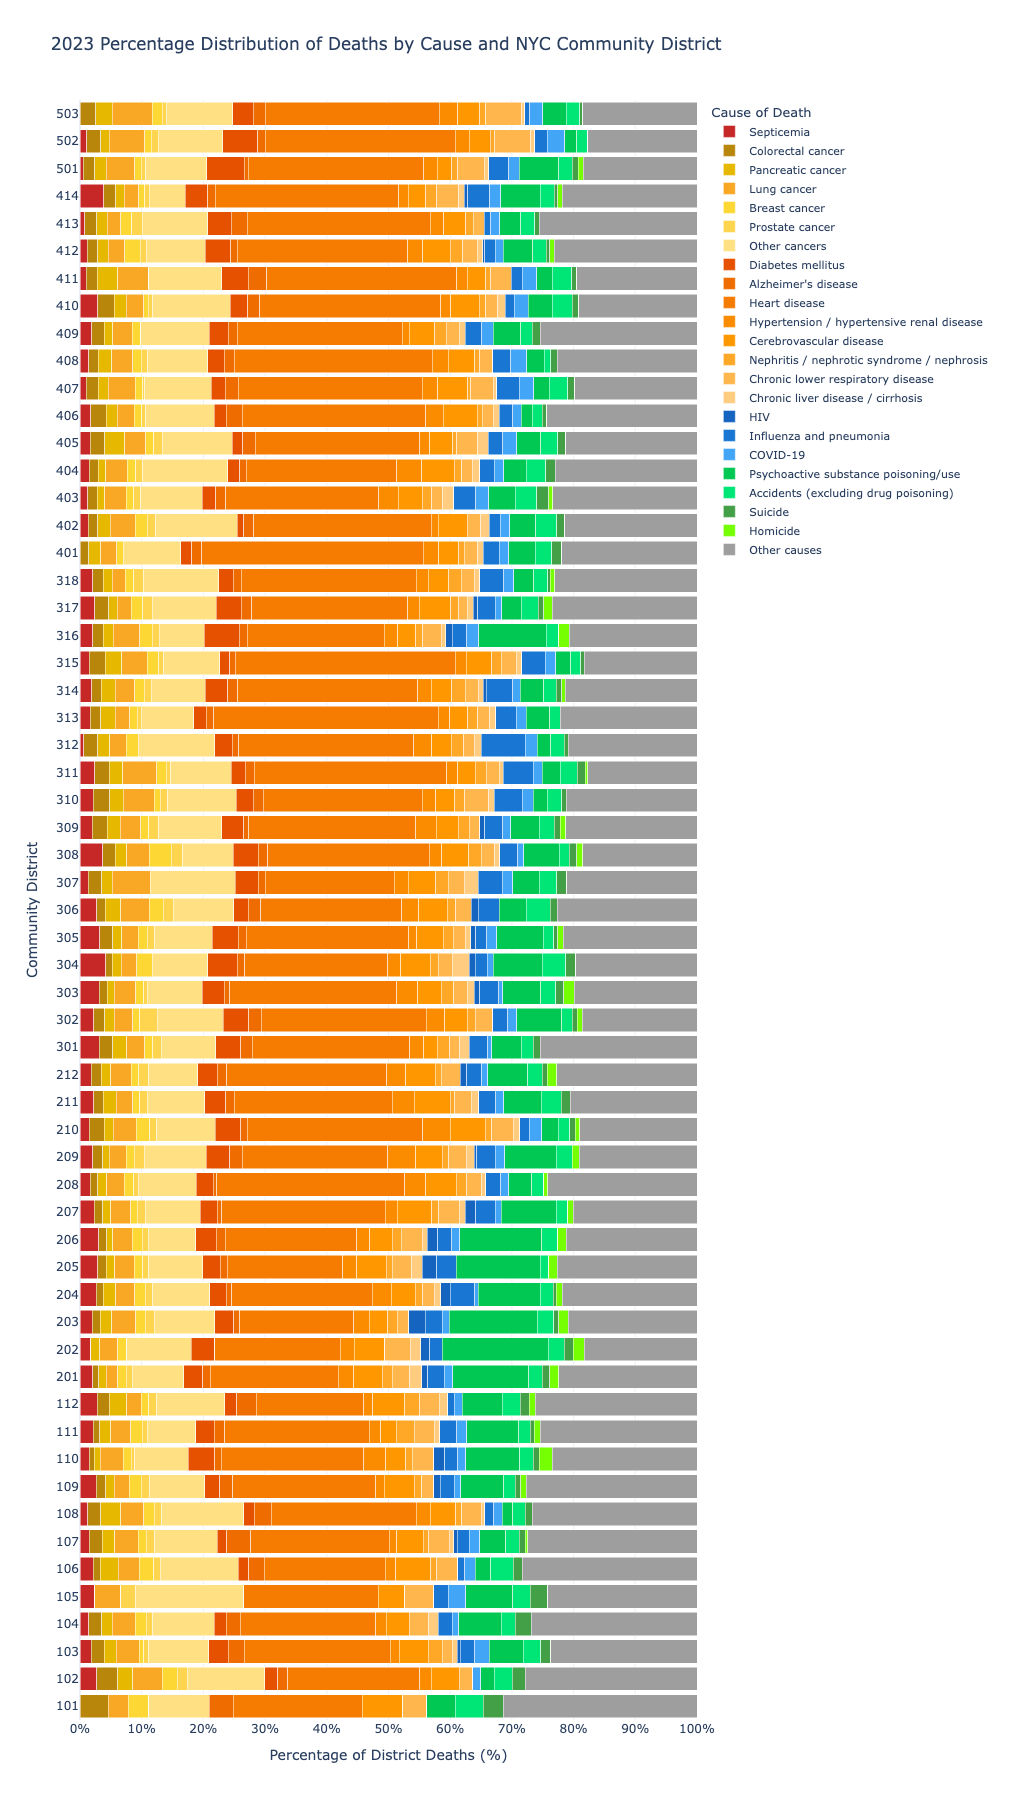

In [25]:

import pandas as pd
import numpy as np
import plotly.express as px

# -----------------------------------------
# 1. LOAD DATA
# -----------------------------------------

df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")

# Cause-of-death columns and readable labels
cause_labels = {
    "Deaths due to septicemia": "Septicemia",
    "Deaths due to HIV": "HIV",
    "Deaths due to malignant neoplasms(cancer)": "Cancer (all malignant neoplasms)",
    "Deaths due to cancer of the colon_ rectum_ and anus": "Colorectal cancer",
    "Deaths due to cancer of the pancreas": "Pancreatic cancer",
    "Deaths due to cancer of trachea_ bronchus_ and lung": "Lung cancer",
    "Deaths due to cancer of the breast": "Breast cancer",
    "Deaths due to cancer of the prostate": "Prostate cancer",
    "Deaths due to diabetes mellitus": "Diabetes mellitus",
    "Deaths due to use of or poisoning by psychoactive substance excluding alcohol and tobacco": "Psychoactive substance poisoning/use",
    "Deaths due to Alzheimer's disease": "Alzheimer's disease",
    "Deaths due to diseases of the heart": "Heart disease",
    "Deaths due to essential hypertension and hypertensive renal disease": "Hypertension / hypertensive renal disease",
    "Deaths due to cerebrovascular diseases": "Cerebrovascular disease",
    "Deaths due to influenza and pneumonia": "Influenza and pneumonia",
    "Deaths due to chronic lower respiratory diseases": "Chronic lower respiratory disease",
    "Deaths due to chronic liver disease and cirrhosis": "Chronic liver disease / cirrhosis",
    "Deaths due to Nephritis_ Nephrotic Syndrome and Nephrosis": "Nephritis / nephrotic syndrome / nephrosis",
    "Deaths due to Covid19": "COVID-19",
    "Deaths due to accidents except for durg poisoning": "Accidents (excluding drug poisoning)",
    "Deaths due to intentional self-harm(suicide)": "Suicide",
    "Deaths due to assault(homicide)": "Homicide",
    "Other causes": "Other causes"
}

# -----------------------------------------
# 2. DEFINE CUSTOM COLORS
# -----------------------------------------

cause_color_map = {

    # SEPTICEMIA - RED
    "Septicemia": "#C62828",

    # CANCERS - DISTINCT SHADES OF YELLOW
    "Colorectal cancer": "#B8860B",
    "Pancreatic cancer": "#E6B800",
    "Lung cancer": "#F9A825",
    "Breast cancer": "#FDD835",
    "Prostate cancer": "#FFD54F",
    "Other cancers": "#FFE082",

    # CHRONIC DISEASES - ORANGE
    "Diabetes mellitus": "#E65100",
    "Alzheimer's disease": "#EF6C00",
    "Heart disease": "#F57C00",
    "Hypertension / hypertensive renal disease": "#FB8C00",
    "Cerebrovascular disease": "#FF9800",
    "Nephritis / nephrotic syndrome / nephrosis": "#FFA726",
    "Chronic lower respiratory disease": "#FFB74D",
    "Chronic liver disease / cirrhosis": "#FFCC80",

    # INFECTIOUS DISEASES - BLUE
    "HIV": "#1565C0",
    "Influenza and pneumonia": "#1976D2",
    "COVID-19": "#42A5F5",

    # NON-NATURAL DEATHS - BRIGHT GREEN
    "Psychoactive substance poisoning/use": "#00C853",
    "Accidents (excluding drug poisoning)": "#00E676",
    "Suicide": "#43A047",
    "Homicide": "#76FF03",

    # OTHER CAUSES - GREY
    "Other causes": "#9E9E9E"
}

# -----------------------------------------
# 3. CLEAN NUMERIC DATA
# -----------------------------------------

cause_columns = list(cause_labels.keys())

missing = [
    col for col in cause_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in cause_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

df["commntydst"] = (
    df["commntydst"].astype(str).str.strip()
)

# -----------------------------------------
# 4. CALCULATE OTHER CANCERS
# -----------------------------------------

all_cancer_col = "Deaths due to malignant neoplasms(cancer)"

specific_cancer_cols = [
    "Deaths due to cancer of the colon_ rectum_ and anus",
    "Deaths due to cancer of the pancreas",
    "Deaths due to cancer of trachea_ bronchus_ and lung",
    "Deaths due to cancer of the breast",
    "Deaths due to cancer of the prostate"
]

# Calculate remaining cancer deaths
df["Other cancers"] = (
    df[all_cancer_col] -
    df[specific_cancer_cols].sum(axis=1)
)

# Check for negative values, which would indicate
# inconsistent or overlapping source counts
negative_cancers = df["Other cancers"] < 0

if negative_cancers.any():
    raise ValueError(
        "Some rows have more site-specific cancer deaths "
        "than total cancer deaths. Check source data."
    )

# -----------------------------------------
# 5. AGGREGATE BY COMMUNITY DISTRICT
# -----------------------------------------

# Exclude overall cancer total to prevent double-counting
chart_columns = [
    col for col in cause_columns
    if col != all_cancer_col
]

# Add calculated Other cancers
chart_columns.append("Other cancers")

df_grouped = df.groupby(
    "commntydst", as_index=False
)[chart_columns].sum()

# Convert wide data into long format
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=chart_columns,
    var_name="Cause of Death",
    value_name="Count"
)

# Apply readable labels
df_long["Cause Label"] = (
    df_long["Cause of Death"].map(cause_labels)
)

# Label calculated Other cancers
df_long.loc[
    df_long["Cause of Death"] == "Other cancers",
    "Cause Label"
] = "Other cancers"

# -----------------------------------------
# 6. CALCULATE PERCENTAGES
# -----------------------------------------

# Total categorized deaths by district
df_long["District_Total"] = df_long.groupby(
    "commntydst"
)["Count"].transform("sum")

# Percentage within district
df_long["Percentage"] = (
    df_long["Count"] /
    df_long["District_Total"].replace(0, np.nan)
    * 100
).fillna(0)

# -----------------------------------------
# 7. ORDER CAUSES BY COLOR GROUP
# -----------------------------------------

cause_order = [

    # Red
    "Septicemia",

    # Yellow
    "Colorectal cancer",
    "Pancreatic cancer",
    "Lung cancer",
    "Breast cancer",
    "Prostate cancer",
    "Other cancers",

    # Orange
    "Diabetes mellitus",
    "Alzheimer's disease",
    "Heart disease",
    "Hypertension / hypertensive renal disease",
    "Cerebrovascular disease",
    "Nephritis / nephrotic syndrome / nephrosis",
    "Chronic lower respiratory disease",
    "Chronic liver disease / cirrhosis",

    # Blue
    "HIV",
    "Influenza and pneumonia",
    "COVID-19",

    # Green
    "Psychoactive substance poisoning/use",
    "Accidents (excluding drug poisoning)",
    "Suicide",
    "Homicide",

    # Grey
    "Other causes"
]

# Sort community districts numerically
districts = sorted(
    df_grouped["commntydst"].unique(),
    key=lambda x: int(x) if x.isdigit() else float("inf")
)

# -----------------------------------------
# 8. CREATE HORIZONTAL STACKED BAR CHART
# -----------------------------------------

fig = px.bar(
    df_long,
    x="Percentage",
    y="commntydst",
    color="Cause Label",
    orientation="h",
    barmode="stack",

    title=(
        "2023 Percentage Distribution of Deaths "
        "by Cause and NYC Community District"
    ),

    labels={
        "Percentage": "Percentage of District Deaths (%)",
        "commntydst": "Community District",
        "Cause Label": "Cause of Death"
    },

    color_discrete_map=cause_color_map,

    category_orders={
        "Cause Label": cause_order,
        "commntydst": districts
    },

    custom_data=["Count", "District_Total"],

    height=1800
)

# -----------------------------------------
# 9. CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{y}<br>"
        "<b>Cause of Death:</b> %{fullData.name}<br>"
        "<b>Percentage of District Deaths:</b> %{x:.2f}%<br>"
        "<b>Death Count:</b> %{customdata[0]:,.0f}<br>"
        "<b>Total Categorized Deaths:</b> %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

# -----------------------------------------
# 10. CUSTOMIZE CHART LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="Percentage of District Deaths (%)",
    yaxis_title="Community District",
    legend_title="Cause of Death",
    bargap=0.15,
    template="plotly_white",
    hovermode="closest",
    height=1800,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11)
    ),

    margin=dict(
        l=80,
        r=320,
        t=100,
        b=80
    )
)

# Percentage axis from 0 to 100
fig.update_xaxes(
    range=[0, 100],
    ticksuffix="%",
    dtick=10
)

# Community districts as categories
fig.update_yaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts
)

# -----------------------------------------
# 11. DISPLAY CHART
# -----------------------------------------

fig.show()


/var/folders/pl/hh80xm6x4hvcgdgydq01cwt00000gn/T/ipykernel_2207/1915834233.py:167: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Other cancers"] = (


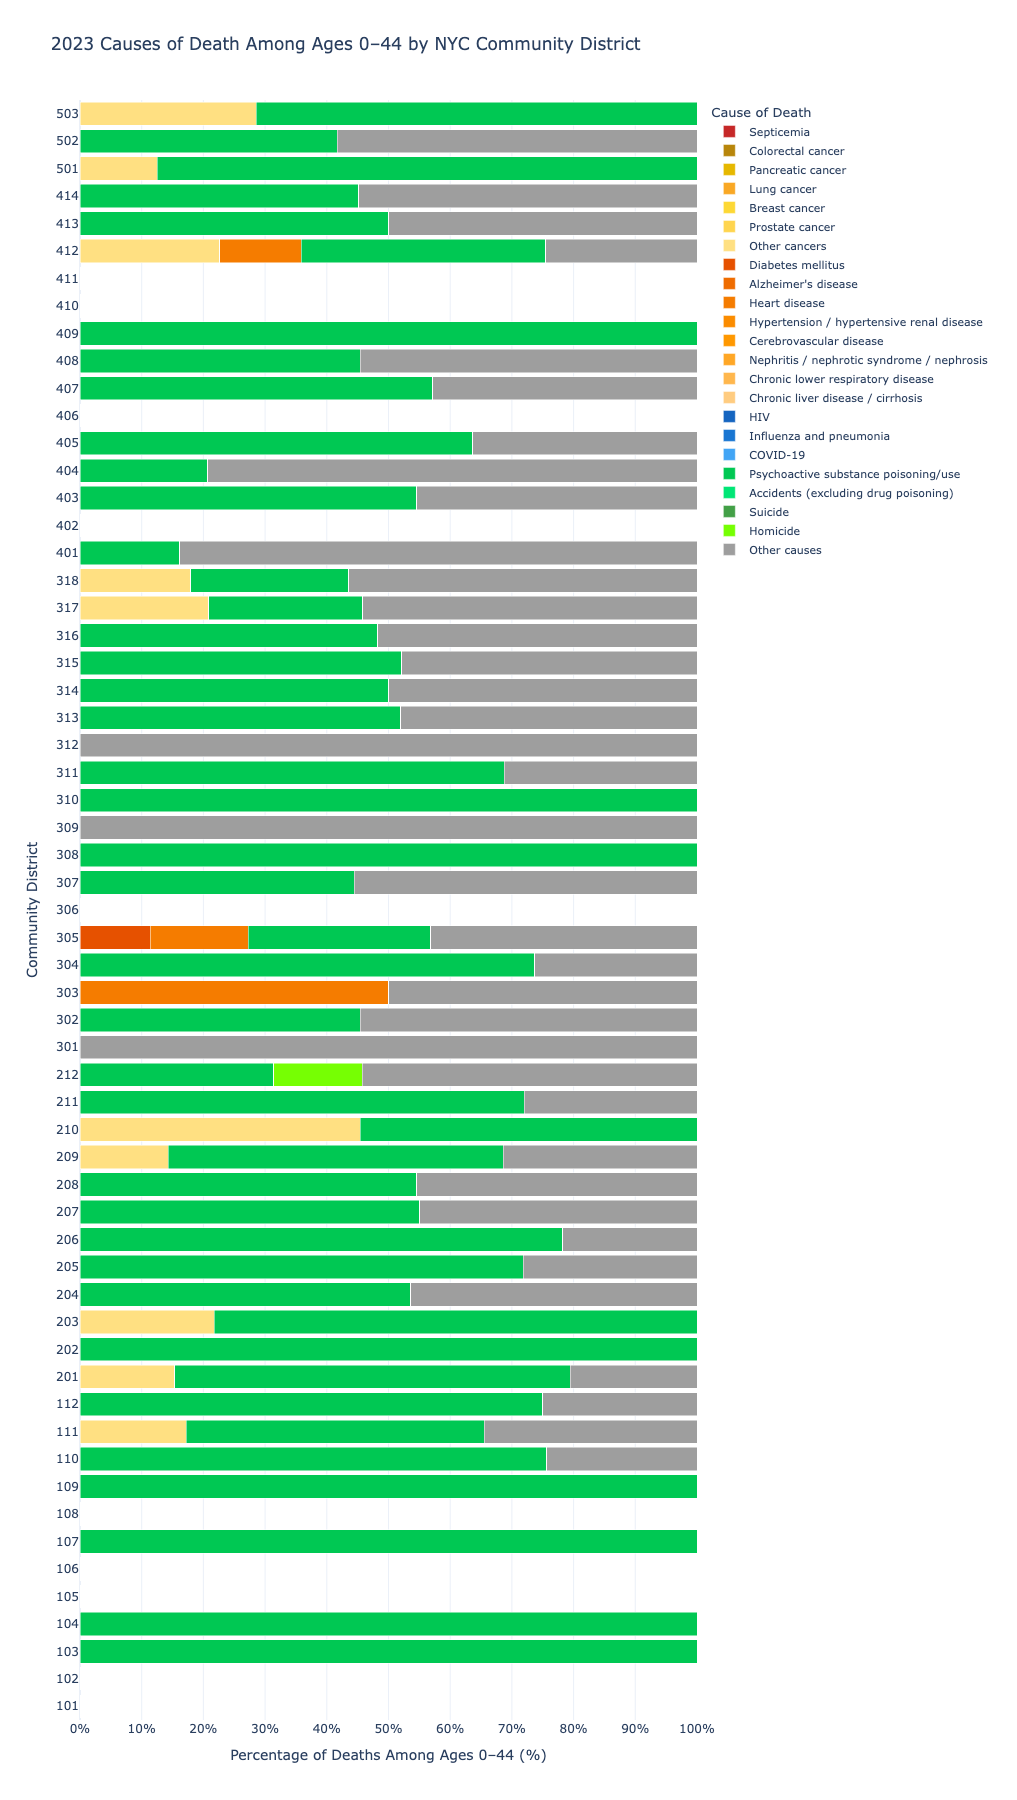

In [26]:

import pandas as pd
import numpy as np
import plotly.express as px

# -----------------------------------------
# 1. LOAD DATA
# -----------------------------------------

df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")
df.columns = df.columns.str.strip()

# -----------------------------------------
# 2. DEFINE AGE GROUPS: 0 THROUGH 44
# -----------------------------------------

age_groups = [
    "Age<=28days",
    "Age 1-12months",
    "Age 1-4",
    "Age 5-9",
    "Age 10-14",
    "Age 15-19",
    "Age 20-24",
    "Age 25-29",
    "Age 30-34",
    "Age 35-39",
    "Age 40-44"
]

# -----------------------------------------
# 3. CAUSE LABELS
# -----------------------------------------

cause_labels = {
    "Deaths due to septicemia": "Septicemia",
    "Deaths due to HIV": "HIV",
    "Deaths due to malignant neoplasms(cancer)": "Cancer (all malignant neoplasms)",
    "Deaths due to cancer of the colon_ rectum_ and anus": "Colorectal cancer",
    "Deaths due to cancer of the pancreas": "Pancreatic cancer",
    "Deaths due to cancer of trachea_ bronchus_ and lung": "Lung cancer",
    "Deaths due to cancer of the breast": "Breast cancer",
    "Deaths due to cancer of the prostate": "Prostate cancer",
    "Deaths due to diabetes mellitus": "Diabetes mellitus",
    "Deaths due to use of or poisoning by psychoactive substance excluding alcohol and tobacco": "Psychoactive substance poisoning/use",
    "Deaths due to Alzheimer's disease": "Alzheimer's disease",
    "Deaths due to diseases of the heart": "Heart disease",
    "Deaths due to essential hypertension and hypertensive renal disease": "Hypertension / hypertensive renal disease",
    "Deaths due to cerebrovascular diseases": "Cerebrovascular disease",
    "Deaths due to influenza and pneumonia": "Influenza and pneumonia",
    "Deaths due to chronic lower respiratory diseases": "Chronic lower respiratory disease",
    "Deaths due to chronic liver disease and cirrhosis": "Chronic liver disease / cirrhosis",
    "Deaths due to Nephritis_ Nephrotic Syndrome and Nephrosis": "Nephritis / nephrotic syndrome / nephrosis",
    "Deaths due to Covid19": "COVID-19",
    "Deaths due to accidents except for durg poisoning": "Accidents (excluding drug poisoning)",
    "Deaths due to intentional self-harm(suicide)": "Suicide",
    "Deaths due to assault(homicide)": "Homicide",
    "Other causes": "Other causes"
}

# -----------------------------------------
# 4. CUSTOM COLOR PALETTE
# -----------------------------------------

cause_color_map = {
    # RED
    "Septicemia": "#C62828",

    # YELLOW - SIX CANCER CATEGORIES
    "Colorectal cancer": "#B8860B",
    "Pancreatic cancer": "#E6B800",
    "Lung cancer": "#F9A825",
    "Breast cancer": "#FDD835",
    "Prostate cancer": "#FFD54F",
    "Other cancers": "#FFE082",

    # ORANGE - CHRONIC DISEASES
    "Diabetes mellitus": "#E65100",
    "Alzheimer's disease": "#EF6C00",
    "Heart disease": "#F57C00",
    "Hypertension / hypertensive renal disease": "#FB8C00",
    "Cerebrovascular disease": "#FF9800",
    "Nephritis / nephrotic syndrome / nephrosis": "#FFA726",
    "Chronic lower respiratory disease": "#FFB74D",
    "Chronic liver disease / cirrhosis": "#FFCC80",

    # BLUE - INFECTIOUS DISEASES
    "HIV": "#1565C0",
    "Influenza and pneumonia": "#1976D2",
    "COVID-19": "#42A5F5",

    # GREEN - NON-NATURAL DEATHS
    "Psychoactive substance poisoning/use": "#00C853",
    "Accidents (excluding drug poisoning)": "#00E676",
    "Suicide": "#43A047",
    "Homicide": "#76FF03",

    # GREY
    "Other causes": "#9E9E9E"
}

# -----------------------------------------
# 5. FIND AGE-SPECIFIC CAUSE COLUMNS
# -----------------------------------------

# Expected format:
# "Deaths due to septicemia_Age 40-44"

age_cause_columns = {}

for cause in cause_labels:
    matching_columns = [
        f"{cause}_{age}"
        for age in age_groups
    ]

    age_cause_columns[cause] = matching_columns

# Validate column names
missing = [
    col
    for cols in age_cause_columns.values()
    for col in cols
    if col not in df.columns
]

if missing:
    print("Missing age-specific cause columns:")
    print(*missing[:30], sep="\n")
    raise ValueError(
        "Column names do not match the expected format. "
        "Check df.columns for the actual names."
    )

# -----------------------------------------
# 6. SUM DEATHS AGED 0-44 FOR EACH CAUSE
# -----------------------------------------

for cause, columns in age_cause_columns.items():

    numeric_values = df[columns].apply(
        lambda s: pd.to_numeric(
            s.astype(str).str.replace(
                ",", "", regex=False
            ),
            errors="coerce"
        )
    ).fillna(0)

    df[cause] = numeric_values.sum(axis=1)

# -----------------------------------------
# 7. CALCULATE OTHER CANCERS
# -----------------------------------------

all_cancer_col = (
    "Deaths due to malignant neoplasms(cancer)"
)

specific_cancer_cols = [
    "Deaths due to cancer of the colon_ rectum_ and anus",
    "Deaths due to cancer of the pancreas",
    "Deaths due to cancer of trachea_ bronchus_ and lung",
    "Deaths due to cancer of the breast",
    "Deaths due to cancer of the prostate"
]

df["Other cancers"] = (
    df[all_cancer_col]
    - df[specific_cancer_cols].sum(axis=1)
)

if (df["Other cancers"] < 0).any():
    raise ValueError(
        "Site-specific cancer deaths exceed overall "
        "cancer deaths in some rows. Check the data."
    )

# -----------------------------------------
# 8. AGGREGATE BY COMMUNITY DISTRICT
# -----------------------------------------

df["commntydst"] = (
    df["commntydst"].astype(str).str.strip()
)

# Exclude overall cancer total to prevent double-counting
chart_columns = [
    cause for cause in cause_labels
    if cause != all_cancer_col
]

chart_columns.append("Other cancers")

df_grouped = df.groupby(
    "commntydst", as_index=False
)[chart_columns].sum()

# Convert to long format
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=chart_columns,
    var_name="Cause",
    value_name="Count"
)

df_long["Cause Label"] = (
    df_long["Cause"].map(cause_labels)
    .fillna(df_long["Cause"])
)

# -----------------------------------------
# 9. CALCULATE PERCENTAGES
# -----------------------------------------

df_long["District_Total"] = (
    df_long.groupby("commntydst")["Count"]
    .transform("sum")
)

df_long["Percentage"] = (
    df_long["Count"]
    / df_long["District_Total"].replace(0, np.nan)
    * 100
).fillna(0)

# -----------------------------------------
# 10. ORDER CAUSES
# -----------------------------------------

cause_order = [
    "Septicemia",

    "Colorectal cancer",
    "Pancreatic cancer",
    "Lung cancer",
    "Breast cancer",
    "Prostate cancer",
    "Other cancers",

    "Diabetes mellitus",
    "Alzheimer's disease",
    "Heart disease",
    "Hypertension / hypertensive renal disease",
    "Cerebrovascular disease",
    "Nephritis / nephrotic syndrome / nephrosis",
    "Chronic lower respiratory disease",
    "Chronic liver disease / cirrhosis",

    "HIV",
    "Influenza and pneumonia",
    "COVID-19",

    "Psychoactive substance poisoning/use",
    "Accidents (excluding drug poisoning)",
    "Suicide",
    "Homicide",

    "Other causes"
]

districts = sorted(
    df_grouped["commntydst"].unique(),
    key=lambda x: (
        0, int(x)
    ) if x.isdigit() else (1, x)
)

# -----------------------------------------
# 11. CREATE HORIZONTAL STACKED BAR CHART
# -----------------------------------------

fig = px.bar(
    df_long,
    x="Percentage",
    y="commntydst",
    color="Cause Label",
    orientation="h",
    barmode="stack",

    title=(
        "2023 Causes of Death Among Ages 0–44 "
        "by NYC Community District"
    ),

    labels={
        "Percentage": "Percentage of Deaths (%)",
        "commntydst": "Community District",
        "Cause Label": "Cause of Death"
    },

    color_discrete_map=cause_color_map,

    category_orders={
        "Cause Label": cause_order,
        "commntydst": districts
    },

    custom_data=["Count", "District_Total"],

    height=1800
)

# -----------------------------------------
# 12. CUSTOM HOVER DETAILS
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{y}<br>"
        "<b>Age Range:</b> 0–44<br>"
        "<b>Cause of Death:</b> %{fullData.name}<br>"
        "<b>Percentage of Deaths:</b> %{x:.2f}%<br>"
        "<b>Death Count:</b> %{customdata[0]:,.0f}<br>"
        "<b>Total Categorized Deaths (0–44):</b> "
        "%{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

# -----------------------------------------
# 13. CUSTOMIZE LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="Percentage of Deaths Among Ages 0–44 (%)",
    yaxis_title="Community District",
    legend_title="Cause of Death",
    bargap=0.15,
    template="plotly_white",
    hovermode="closest",
    height=1800,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11)
    ),

    margin=dict(
        l=80,
        r=320,
        t=100,
        b=80
    )
)

fig.update_xaxes(
    range=[0, 100],
    ticksuffix="%",
    dtick=10
)

fig.update_yaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts
)

# -----------------------------------------
# 14. DISPLAY CHART
# -----------------------------------------

fig.show()


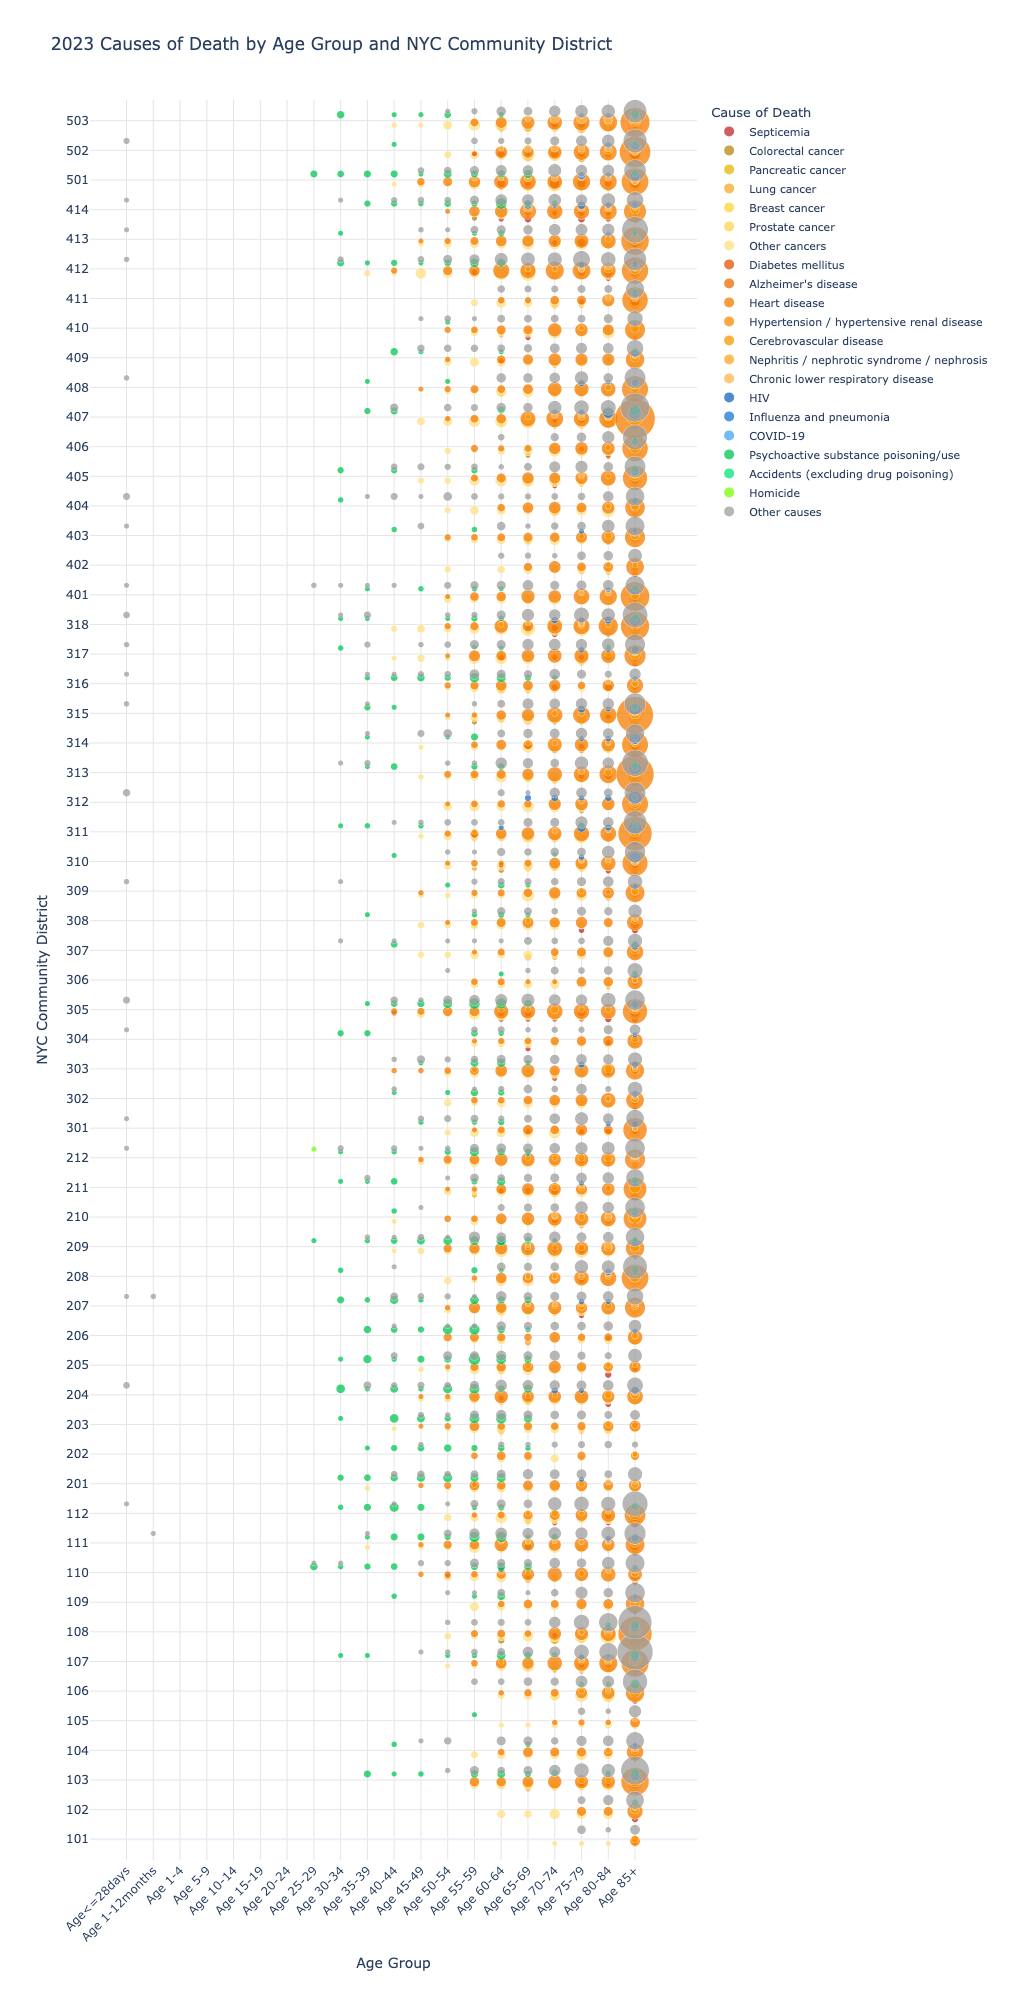

In [28]:

import pandas as pd
import numpy as np
import plotly.express as px

# -----------------------------------------
# 1. LOAD DATA
# -----------------------------------------

df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")
df.columns = df.columns.str.strip()

# -----------------------------------------
# 2. DEFINE AGE GROUPS
# -----------------------------------------

age_groups = [
    "Age<=28days",
    "Age 1-12months",
    "Age 1-4",
    "Age 5-9",
    "Age 10-14",
    "Age 15-19",
    "Age 20-24",
    "Age 25-29",
    "Age 30-34",
    "Age 35-39",
    "Age 40-44",
    "Age 45-49",
    "Age 50-54",
    "Age 55-59",
    "Age 60-64",
    "Age 65-69",
    "Age 70-74",
    "Age 75-79",
    "Age 80-84",
    "Age 85+"
]

# -----------------------------------------
# 3. CAUSE-OF-DEATH LABELS
# -----------------------------------------

cause_labels = {
    "Deaths due to septicemia": "Septicemia",
    "Deaths due to HIV": "HIV",
    "Deaths due to malignant neoplasms(cancer)": "Cancer (all malignant neoplasms)",
    "Deaths due to cancer of the colon_ rectum_ and anus": "Colorectal cancer",
    "Deaths due to cancer of the pancreas": "Pancreatic cancer",
    "Deaths due to cancer of trachea_ bronchus_ and lung": "Lung cancer",
    "Deaths due to cancer of the breast": "Breast cancer",
    "Deaths due to cancer of the prostate": "Prostate cancer",
    "Deaths due to diabetes mellitus": "Diabetes mellitus",
    "Deaths due to use of or poisoning by psychoactive substance excluding alcohol and tobacco": "Psychoactive substance poisoning/use",
    "Deaths due to Alzheimer's disease": "Alzheimer's disease",
    "Deaths due to diseases of the heart": "Heart disease",
    "Deaths due to essential hypertension and hypertensive renal disease": "Hypertension / hypertensive renal disease",
    "Deaths due to cerebrovascular diseases": "Cerebrovascular disease",
    "Deaths due to influenza and pneumonia": "Influenza and pneumonia",
    "Deaths due to chronic lower respiratory diseases": "Chronic lower respiratory disease",
    "Deaths due to chronic liver disease and cirrhosis": "Chronic liver disease / cirrhosis",
    "Deaths due to Nephritis_ Nephrotic Syndrome and Nephrosis": "Nephritis / nephrotic syndrome / nephrosis",
    "Deaths due to Covid19": "COVID-19",
    "Deaths due to accidents except for durg poisoning": "Accidents (excluding drug poisoning)",
    "Deaths due to intentional self-harm(suicide)": "Suicide",
    "Deaths due to assault(homicide)": "Homicide",
    "Other causes": "Other causes"
}

# -----------------------------------------
# 4. SAME CUSTOM COLOR PALETTE
# -----------------------------------------

cause_color_map = {
    # RED - SEPTICEMIA
    "Septicemia": "#C62828",

    # YELLOW - CANCERS
    "Colorectal cancer": "#B8860B",
    "Pancreatic cancer": "#E6B800",
    "Lung cancer": "#F9A825",
    "Breast cancer": "#FDD835",
    "Prostate cancer": "#FFD54F",
    "Other cancers": "#FFE082",

    # ORANGE - CHRONIC DISEASES
    "Diabetes mellitus": "#E65100",
    "Alzheimer's disease": "#EF6C00",
    "Heart disease": "#F57C00",
    "Hypertension / hypertensive renal disease": "#FB8C00",
    "Cerebrovascular disease": "#FF9800",
    "Nephritis / nephrotic syndrome / nephrosis": "#FFA726",
    "Chronic lower respiratory disease": "#FFB74D",
    "Chronic liver disease / cirrhosis": "#FFCC80",

    # BLUE - INFECTIOUS DISEASES
    "HIV": "#1565C0",
    "Influenza and pneumonia": "#1976D2",
    "COVID-19": "#42A5F5",

    # GREEN - NON-NATURAL DEATHS
    "Psychoactive substance poisoning/use": "#00C853",
    "Accidents (excluding drug poisoning)": "#00E676",
    "Suicide": "#43A047",
    "Homicide": "#76FF03",

    # GREY - OTHER CAUSES
    "Other causes": "#9E9E9E"
}

# -----------------------------------------
# 5. FIND CAUSE-BY-AGE COLUMNS
# -----------------------------------------

# Expected naming pattern:
# "Deaths due to septicemia_Age 40-44"

age_cause_columns = {}

for cause in cause_labels:
    age_cause_columns[cause] = [
        f"{cause}_{age}"
        for age in age_groups
    ]

# Validate columns before proceeding
missing = [
    col
    for cols in age_cause_columns.values()
    for col in cols
    if col not in df.columns
]

if missing:
    print("Missing cause-by-age columns:")
    print(*missing[:40], sep="\n")
    raise ValueError(
        "Some column names do not match the expected "
        "cause-by-age naming convention. "
        "Inspect df.columns to identify the differences."
    )

# -----------------------------------------
# 6. RESHAPE TO LONG FORMAT
# -----------------------------------------

records = []

for cause, columns in age_cause_columns.items():

    for age, col in zip(age_groups, columns):

        temp = df[["commntydst", col]].copy()

        temp["Count"] = pd.to_numeric(
            temp[col].astype(str).str.replace(
                ",", "", regex=False
            ),
            errors="coerce"
        ).fillna(0)

        temp["Age Group"] = age
        temp["Cause"] = cause_labels[cause]

        records.append(
            temp[["commntydst", "Age Group", "Cause", "Count"]]
        )

df_long = pd.concat(records, ignore_index=True)

# Clean district codes
df_long["commntydst"] = (
    df_long["commntydst"].astype(str).str.strip()
)

# Aggregate counts if districts have multiple rows
df_long = df_long.groupby(
    ["commntydst", "Age Group", "Cause"],
    as_index=False
)["Count"].sum()

# -----------------------------------------
# 7. CALCULATE OTHER CANCERS BY AGE
# -----------------------------------------

cancer_causes = [
    "Colorectal cancer",
    "Pancreatic cancer",
    "Lung cancer",
    "Breast cancer",
    "Prostate cancer"
]

# Total cancer deaths by district and age
all_cancers = df_long[
    df_long["Cause"] == "Cancer (all malignant neoplasms)"
][["commntydst", "Age Group", "Count"]].rename(
    columns={"Count": "All_Cancers"}
)

# Sum site-specific cancer deaths
specific_cancers = (
    df_long[df_long["Cause"].isin(cancer_causes)]
    .groupby(["commntydst", "Age Group"], as_index=False)
    ["Count"].sum()
    .rename(columns={"Count": "Specific_Cancers"})
)

# Calculate residual cancer deaths
other_cancers = all_cancers.merge(
    specific_cancers,
    on=["commntydst", "Age Group"],
    how="left"
)

other_cancers["Specific_Cancers"] = (
    other_cancers["Specific_Cancers"].fillna(0)
)

other_cancers["Count"] = (
    other_cancers["All_Cancers"]
    - other_cancers["Specific_Cancers"]
)

if (other_cancers["Count"] < 0).any():
    raise ValueError(
        "Site-specific cancer counts exceed total cancer "
        "counts for some district-age combinations."
    )

other_cancers["Cause"] = "Other cancers"

other_cancers = other_cancers[
    ["commntydst", "Age Group", "Cause", "Count"]
]

# Remove overall cancer total to avoid double-counting
df_long = df_long[
    df_long["Cause"] != "Cancer (all malignant neoplasms)"
].copy()

# Add Other cancers
df_long = pd.concat(
    [df_long, other_cancers],
    ignore_index=True
)

# -----------------------------------------
# 8. REMOVE ZERO-COUNT OBSERVATIONS
# -----------------------------------------

# No bubble is displayed where no deaths were recorded
df_long = df_long[df_long["Count"] > 0].copy()

# -----------------------------------------
# 9. SORT DISTRICTS AND AGES
# -----------------------------------------

districts = sorted(
    df_long["commntydst"].unique(),
    key=lambda x: (
        0, int(x)
    ) if x.isdigit() else (1, x)
)

age_order = age_groups

# -----------------------------------------
# 10. ADD SMALL OFFSETS TO REDUCE OVERLAP
# -----------------------------------------

# Assign numeric positions to each district
district_positions = {
    district: i
    for i, district in enumerate(districts)
}

df_long["District_Position"] = (
    df_long["commntydst"].map(district_positions)
)

# Give each cause a small vertical offset.
# This separates overlapping bubbles at the same
# district-age coordinate without changing the
# original district shown on hover.

cause_order = list(cause_color_map.keys())

offsets = np.linspace(
    -0.32, 0.32, len(cause_order)
)

cause_offsets = dict(zip(cause_order, offsets))

df_long["Y_Position"] = (
    df_long["District_Position"]
    + df_long["Cause"].map(cause_offsets)
)

# -----------------------------------------
# 11. CREATE BUBBLE SCATTER PLOT
# -----------------------------------------

fig = px.scatter(
    df_long,
    x="Age Group",
    y="Y_Position",
    size="Count",
    color="Cause",

    color_discrete_map=cause_color_map,

    category_orders={
        "Age Group": age_order,
        "Cause": cause_order
    },

    custom_data=[
        "commntydst",
        "Age Group",
        "Cause",
        "Count"
    ],

    size_max=40,

    title=(
        "2023 Causes of Death by Age Group "
        "and NYC Community District"
    ),

    height=2000
)

# -----------------------------------------
# 12. CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{customdata[0]}<br>"
        "<b>Age Group:</b> %{customdata[1]}<br>"
        "<b>Cause of Death:</b> %{customdata[2]}<br>"
        "<b>Death Count:</b> %{customdata[3]:,.0f}"
        "<extra></extra>"
    ),
    marker=dict(
        opacity=0.75,
        line=dict(
            width=0.5,
            color="white"
        )
    )
)

# -----------------------------------------
# 13. CUSTOMIZE AXES AND LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="Age Group",
    yaxis_title="NYC Community District",
    legend_title="Cause of Death",
    template="plotly_white",
    hovermode="closest",

    height=2000,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11),
        itemsizing="constant"
    ),

    margin=dict(
        l=90,
        r=320,
        t=100,
        b=140
    )
)

# Show district codes instead of numeric positions
fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(len(districts))),
    ticktext=districts,
    range=[-0.7, len(districts) - 0.3],
    showgrid=True,
    gridcolor="#E5E5E5"
)

fig.update_xaxes(
    categoryorder="array",
    categoryarray=age_order,
    tickangle=-45,
    showgrid=True,
    gridcolor="#E5E5E5"
)

# -----------------------------------------
# 14. DISPLAY INTERACTIVE CHART
# -----------------------------------------

fig.show()


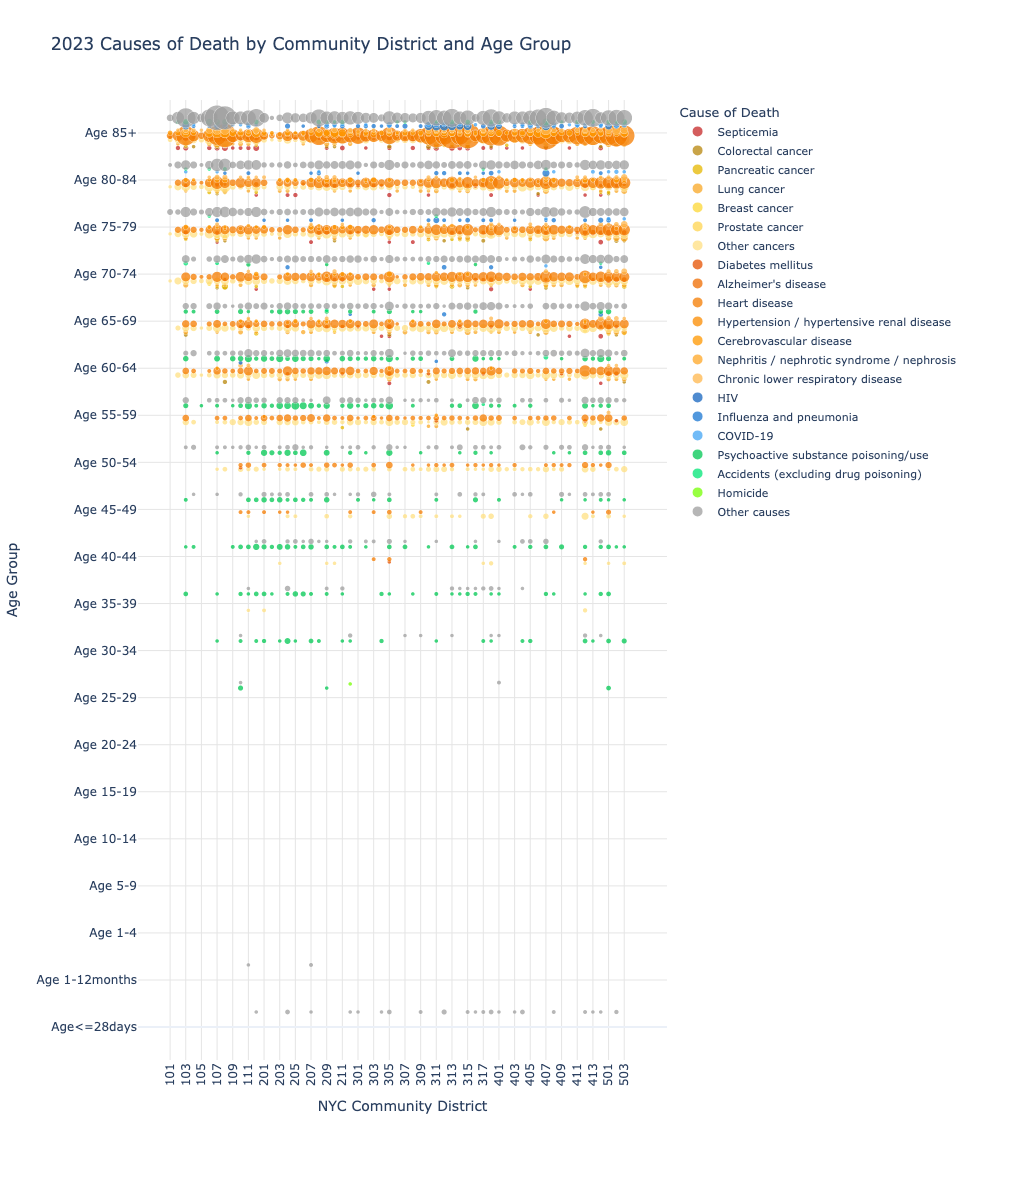

In [30]:
# -----------------------------------------
# 10. ADD OFFSETS TO REDUCE OVERLAP
# -----------------------------------------

# Assign numeric positions to each age group
age_positions = {
    age: i
    for i, age in enumerate(age_groups)
}

df_long["Age_Position"] = (
    df_long["Age Group"].map(age_positions)
)

# Small vertical offsets for different causes
cause_order = list(cause_color_map.keys())

offsets = np.linspace(
    -0.32, 0.32, len(cause_order)
)

cause_offsets = dict(zip(cause_order, offsets))

df_long["Y_Position"] = (
    df_long["Age_Position"]
    + df_long["Cause"].map(cause_offsets)
)

# -----------------------------------------
# 11. CREATE BUBBLE SCATTER PLOT
# -----------------------------------------

fig = px.scatter(
    df_long,
    x="commntydst",
    y="Y_Position",
    size="Count",
    color="Cause",

    color_discrete_map=cause_color_map,

    category_orders={
        "commntydst": districts,
        "Cause": cause_order
    },

    custom_data=[
        "commntydst",
        "Age Group",
        "Cause",
        "Count"
    ],

    size_max=28,

    title=(
        "2023 Causes of Death by Community District "
        "and Age Group"
    ),

    height=1200
)

# -----------------------------------------
# 12. CUSTOMIZE HOVER
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{customdata[0]}<br>"
        "<b>Age Group:</b> %{customdata[1]}<br>"
        "<b>Cause of Death:</b> %{customdata[2]}<br>"
        "<b>Death Count:</b> %{customdata[3]:,.0f}"
        "<extra></extra>"
    ),
    marker=dict(
        opacity=0.75,
        line=dict(width=0.5, color="white")
    )
)

# -----------------------------------------
# 13. CUSTOMIZE AXES AND LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="NYC Community District",
    yaxis_title="Age Group",
    legend_title="Cause of Death",
    template="plotly_white",
    hovermode="closest",

    height=1200,
    width=1800,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11),
        itemsizing="constant"
    ),

    margin=dict(
        l=100,
        r=350,
        t=100,
        b=140
    )
)

# X-axis: community districts
fig.update_xaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts,
    tickangle=-90,
    showgrid=True,
    gridcolor="#E5E5E5"
)

# Y-axis: age groups
fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(len(age_groups))),
    ticktext=age_groups,
    range=[-0.7, len(age_groups) - 0.3],
    showgrid=True,
    gridcolor="#E5E5E5"
)

# -----------------------------------------
# 14. DISPLAY CHART
# -----------------------------------------

fig.show()

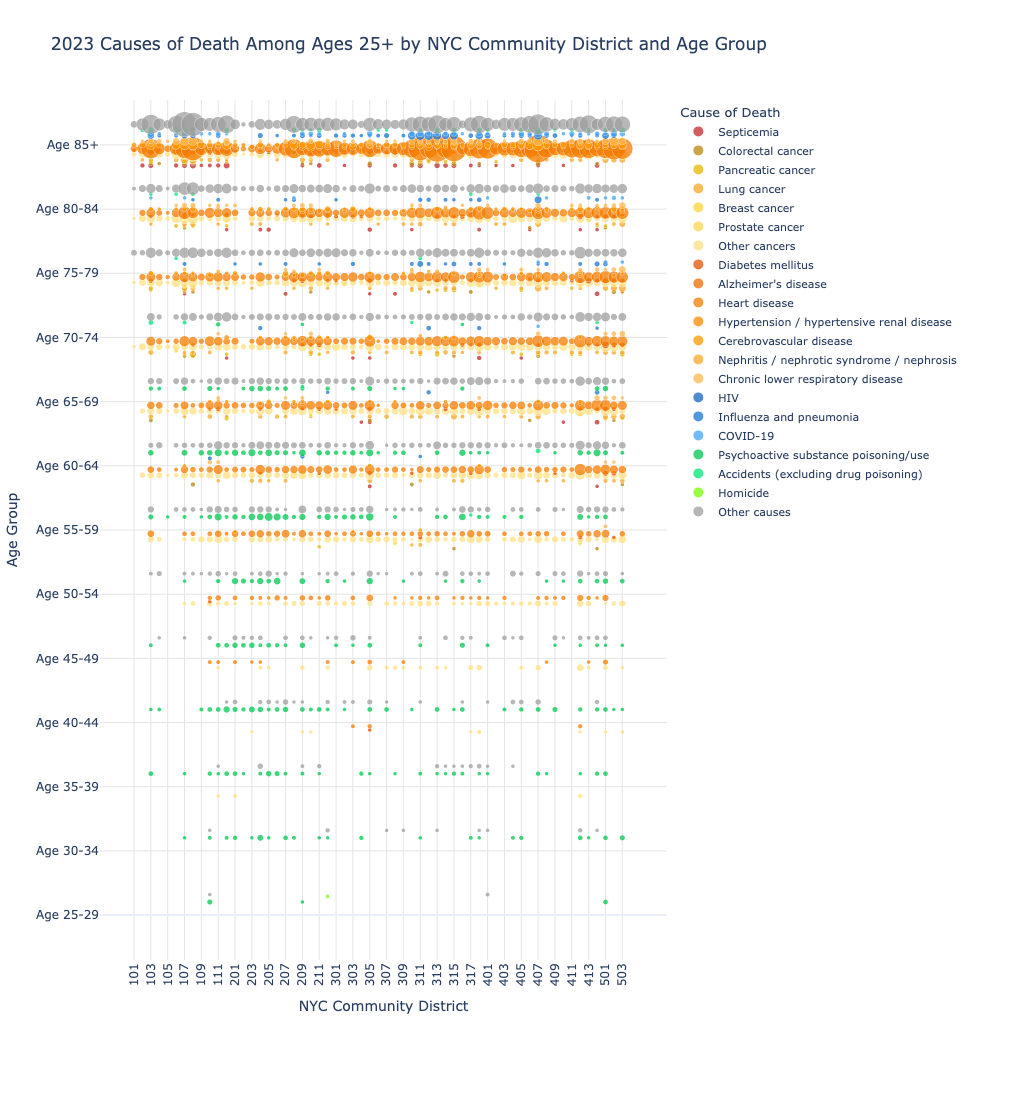

In [31]:
# -----------------------------------------
# 10. FILTER AGE GROUPS: 25 AND UP
# -----------------------------------------

age_groups_25_plus = [
    "Age 25-29",
    "Age 30-34",
    "Age 35-39",
    "Age 40-44",
    "Age 45-49",
    "Age 50-54",
    "Age 55-59",
    "Age 60-64",
    "Age 65-69",
    "Age 70-74",
    "Age 75-79",
    "Age 80-84",
    "Age 85+"
]

# Filter to ages 25 and older
df_plot = df_long[
    df_long["Age Group"].isin(age_groups_25_plus)
].copy()

# -----------------------------------------
# 11. ADD OFFSETS TO REDUCE OVERLAP
# -----------------------------------------

age_positions = {
    age: i
    for i, age in enumerate(age_groups_25_plus)
}

df_plot["Age_Position"] = (
    df_plot["Age Group"].map(age_positions)
)

# Keep the same disease colors and ordering
cause_order = list(cause_color_map.keys())

offsets = np.linspace(
    -0.32, 0.32, len(cause_order)
)

cause_offsets = dict(zip(cause_order, offsets))

df_plot["Y_Position"] = (
    df_plot["Age_Position"]
    + df_plot["Cause"].map(cause_offsets)
)

# -----------------------------------------
# 12. CREATE BUBBLE SCATTER PLOT
# -----------------------------------------

fig = px.scatter(
    df_plot,
    x="commntydst",
    y="Y_Position",
    size="Count",
    color="Cause",

    color_discrete_map=cause_color_map,

    category_orders={
        "commntydst": districts,
        "Cause": cause_order
    },

    custom_data=[
        "commntydst",
        "Age Group",
        "Cause",
        "Count"
    ],

    size_max=28,

    title=(
        "2023 Causes of Death Among Ages 25+ "
        "by NYC Community District and Age Group"
    ),

    height=1100,
    width=1800
)

# -----------------------------------------
# 13. CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{customdata[0]}<br>"
        "<b>Age Group:</b> %{customdata[1]}<br>"
        "<b>Cause of Death:</b> %{customdata[2]}<br>"
        "<b>Death Count:</b> %{customdata[3]:,.0f}"
        "<extra></extra>"
    ),
    marker=dict(
        opacity=0.75,
        line=dict(
            width=0.5,
            color="white"
        )
    )
)

# -----------------------------------------
# 14. CUSTOMIZE AXES AND LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="NYC Community District",
    yaxis_title="Age Group",
    legend_title="Cause of Death",
    template="plotly_white",
    hovermode="closest",

    height=1100,
    width=1800,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11),
        itemsizing="constant"
    ),

    margin=dict(
        l=100,
        r=350,
        t=100,
        b=140
    )
)

# X-axis: Community districts
fig.update_xaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts,
    tickangle=-90,
    showgrid=True,
    gridcolor="#E5E5E5"
)

# Y-axis: Age groups 25+
fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(len(age_groups_25_plus))),
    ticktext=age_groups_25_plus,
    range=[-0.7, len(age_groups_25_plus) - 0.3],
    showgrid=True,
    gridcolor="#E5E5E5"
)

# -----------------------------------------
# 15. DISPLAY CHART
# -----------------------------------------

fig.show()

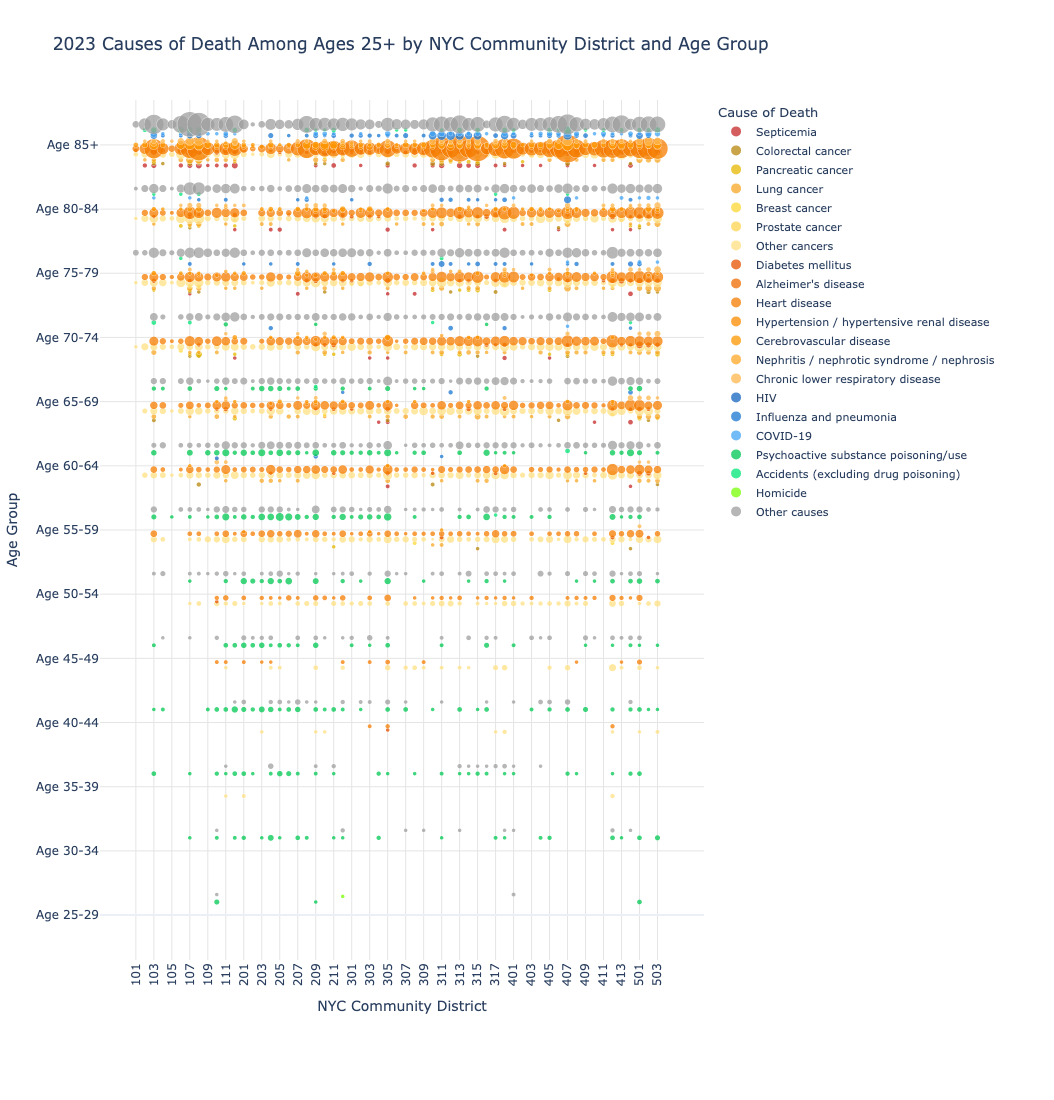

In [32]:
# -----------------------------------------
# 10. FILTER AGE GROUPS: 25 AND UP
# -----------------------------------------

age_groups_25_plus = [
    "Age 25-29",
    "Age 30-34",
    "Age 35-39",
    "Age 40-44",
    "Age 45-49",
    "Age 50-54",
    "Age 55-59",
    "Age 60-64",
    "Age 65-69",
    "Age 70-74",
    "Age 75-79",
    "Age 80-84",
    "Age 85+"
]

# Filter to ages 25 and older
df_plot = df_long[
    df_long["Age Group"].isin(age_groups_25_plus)
].copy()

# -----------------------------------------
# 11. ADD OFFSETS TO REDUCE OVERLAP
# -----------------------------------------

age_positions = {
    age: i
    for i, age in enumerate(age_groups_25_plus)
}

df_plot["Age_Position"] = (
    df_plot["Age Group"].map(age_positions)
)

# Keep the same disease colors and ordering
cause_order = list(cause_color_map.keys())

offsets = np.linspace(
    -0.32, 0.32, len(cause_order)
)

cause_offsets = dict(zip(cause_order, offsets))

df_plot["Y_Position"] = (
    df_plot["Age_Position"]
    + df_plot["Cause"].map(cause_offsets)
)

# -----------------------------------------
# 12. CREATE BUBBLE SCATTER PLOT
# -----------------------------------------

fig = px.scatter(
    df_plot,
    x="commntydst",
    y="Y_Position",
    size="Count",
    color="Cause",

    color_discrete_map=cause_color_map,

    category_orders={
        "commntydst": districts,
        "Cause": cause_order
    },

    custom_data=[
        "commntydst",
        "Age Group",
        "Cause",
        "Count"
    ],

    size_max=28,

    title=(
        "2023 Causes of Death Among Ages 25+ "
        "by NYC Community District and Age Group"
    ),

    height=1100,
    width=1800
)

# -----------------------------------------
# 13. CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{customdata[0]}<br>"
        "<b>Age Group:</b> %{customdata[1]}<br>"
        "<b>Cause of Death:</b> %{customdata[2]}<br>"
        "<b>Death Count:</b> %{customdata[3]:,.0f}"
        "<extra></extra>"
    ),
    marker=dict(
        opacity=0.75,
        line=dict(
            width=0.5,
            color="white"
        )
    )
)

# -----------------------------------------
# 14. CUSTOMIZE AXES AND LAYOUT
# -----------------------------------------

fig.update_layout(
    xaxis_title="NYC Community District",
    yaxis_title="Age Group",
    legend_title="Cause of Death",
    template="plotly_white",
    hovermode="closest",

    height=1100,
    width=1800,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11),
        itemsizing="constant"
    ),

    margin=dict(
        l=100,
        r=350,
        t=100,
        b=140
    )
)

# X-axis: Community districts
fig.update_xaxes(
    type="category",
    categoryorder="array",
    categoryarray=districts,
    tickangle=-90,
    showgrid=True,
    gridcolor="#E5E5E5"
)

# Y-axis: Age groups 25+
fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(len(age_groups_25_plus))),
    ticktext=age_groups_25_plus,
    range=[-0.7, len(age_groups_25_plus) - 0.3],
    showgrid=True,
    gridcolor="#E5E5E5"
)

# -----------------------------------------
# 15. DISPLAY CHART
# -----------------------------------------

fig.show()